## Imports

In [1]:
from IPython.display import display

import numpy as np
from matplotlib import pyplot as plt
import pandas as pd

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from sklearn.model_selection import PredefinedSplit, GridSearchCV

from statsmodels.tsa.deterministic import CalendarFourier, DeterministicProcess

from tensordict import TensorDict
import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader

import xgboost as xgb

import copy
from datetime import timedelta, date
import math
import os
import random

from utils import *

c:\Users\Moral\Documents\Personal Projects\WeatherForecasting\notebooks\utils.py:22: DtypeWarning: Columns (7: ACMH_ATTRIBUTES, 9: ACSH_ATTRIBUTES, 13: FMTM_ATTRIBUTES, 19: PSUN_ATTRIBUTES, 25: TAVG_ATTRIBUTES, 31: TSUN_ATTRIBUTES, 33: WDF1_ATTRIBUTES, 39: WDFG_ATTRIBUTES, 41: WESD_ATTRIBUTES, 43: WSF1_ATTRIBUTES, 49: WSFG_ATTRIBUTES, 57: WT04_ATTRIBUTES, 59: WT05_ATTRIBUTES, 61: WT06_ATTRIBUTES, 63: WT07_ATTRIBUTES, 67: WT09_ATTRIBUTES, 69: WT10_ATTRIBUTES, 71: WT11_ATTRIBUTES, 73: WT13_ATTRIBUTES, 75: WT14_ATTRIBUTES, 77: WT15_ATTRIBUTES, 79: WT16_ATTRIBUTES, 81: WT18_ATTRIBUTES, 83: WT21_ATTRIBUTES, 85: WV03_ATTRIBUTES) have mixed types. Specify dtype option on import or set low_memory=False.
  raw_ghcnd = pd.read_csv(r'../data/raw/GHCND_1980_to_2026.csv')


In [2]:
FIGURES_PATH = r'./figures'
os.makedirs(FIGURES_PATH, exist_ok=True)

In [3]:
SEED = 0

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    # Makes many operations deterministic
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SEED)

## Data Processing

In [4]:
raw_ghcnd = pd.read_csv(r'../data/raw/GHCND_1980_to_2026.csv')
raw_ghcnd["DATE"] = pd.to_datetime(raw_ghcnd["DATE"])

C:\Users\Moral\AppData\Local\Temp\ipykernel_10728\781470718.py:1: DtypeWarning: Columns (7: ACMH_ATTRIBUTES, 9: ACSH_ATTRIBUTES, 13: FMTM_ATTRIBUTES, 19: PSUN_ATTRIBUTES, 25: TAVG_ATTRIBUTES, 31: TSUN_ATTRIBUTES, 33: WDF1_ATTRIBUTES, 39: WDFG_ATTRIBUTES, 41: WESD_ATTRIBUTES, 43: WSF1_ATTRIBUTES, 49: WSFG_ATTRIBUTES, 57: WT04_ATTRIBUTES, 59: WT05_ATTRIBUTES, 61: WT06_ATTRIBUTES, 63: WT07_ATTRIBUTES, 67: WT09_ATTRIBUTES, 69: WT10_ATTRIBUTES, 71: WT11_ATTRIBUTES, 73: WT13_ATTRIBUTES, 75: WT14_ATTRIBUTES, 77: WT15_ATTRIBUTES, 79: WT16_ATTRIBUTES, 81: WT18_ATTRIBUTES, 83: WT21_ATTRIBUTES, 85: WV03_ATTRIBUTES) have mixed types. Specify dtype option on import or set low_memory=False.
  raw_ghcnd = pd.read_csv(r'../data/raw/GHCND_1980_to_2026.csv')


## Baseline Models

### Persistence

In [5]:
persistence_train_df, persistence_val_df, persistence_test_df = persistence_ghcnd_dataset(raw_ghcnd)
persistence_model = PersistenceBaseline()

#### Persistence Metrics

In [6]:
persistence_train_output = persistence_model.predict(persistence_train_df)
persistence_train_metrics = {
    "MAE":  mean_absolute_error(persistence_train_df[["TMAX", "TMIN"]].values, persistence_train_output.values, multioutput="raw_values"),
    "RMSE": root_mean_squared_error(persistence_train_df[["TMAX", "TMIN"]].values, persistence_train_output.values, multioutput="raw_values"),
    "ME":   mean_error(persistence_train_df[["TMAX", "TMIN"]].values, persistence_train_output.values)
}

persistence_val_output = persistence_model.predict(persistence_val_df)
persistence_val_metrics = {
    "MAE":  mean_absolute_error(persistence_val_df[["TMAX", "TMIN"]].values, persistence_val_output.values, multioutput="raw_values"),
    "RMSE": root_mean_squared_error(persistence_val_df[["TMAX", "TMIN"]].values, persistence_val_output.values, multioutput="raw_values"),
    "ME":   mean_error(persistence_val_df[["TMAX", "TMIN"]].values, persistence_val_output.values)
}

persistence_test_output = persistence_model.predict(persistence_test_df)
persistence_test_metrics = {
    "MAE":  mean_absolute_error(persistence_test_df[["TMAX", "TMIN"]].values, persistence_test_output.values, multioutput="raw_values"),
    "RMSE": root_mean_squared_error(persistence_test_df[["TMAX", "TMIN"]].values, persistence_test_output.values, multioutput="raw_values"),
    "ME":   mean_error(persistence_test_df[["TMAX", "TMIN"]].values, persistence_test_output.values)
}

In [7]:
persistence_train_performance_df = persistence_train_output.join(persistence_train_df[["TMAX", "TMIN"]])
persistence_val_performance_df = persistence_val_output.join(persistence_val_df[["TMAX", "TMIN"]])
persistence_test_performance_df = persistence_test_output.join(persistence_test_df[["TMAX", "TMIN"]])

In [8]:
print("Train Metrics: (TMAX/TMIN)")
print(f"- MAE: {persistence_train_metrics["MAE"]}")
print(f"- RMSE: {persistence_train_metrics["RMSE"]}")
print(f"- ME: {persistence_train_metrics["ME"]}\n")

print("Validation Metrics: (TMAX/TMIN)")
print(f"- MAE: {persistence_val_metrics["MAE"]}")
print(f"- RMSE: {persistence_val_metrics["RMSE"]}")
print(f"- ME: {persistence_val_metrics["ME"]}\n")

print("Test Metrics: (TMAX/TMIN)")
print(f"- MAE: {persistence_test_metrics["MAE"]}")
print(f"- RMSE: {persistence_test_metrics["RMSE"]}")
print(f"- ME: {persistence_test_metrics["ME"]}\n")


Train Metrics: (TMAX/TMIN)
- MAE: [3.04531002 3.46422893]
- RMSE: [4.36767405 4.93737499]
- ME: [-0.00167815 -0.00123653]

Validation Metrics: (TMAX/TMIN)
- MAE: [2.94798592 3.08486508]
- RMSE: [4.18182746 4.38345808]
- ME: [0.00312867 0.00312867]

Test Metrics: (TMAX/TMIN)
- MAE: [2.90349076 3.10198494]
- RMSE: [4.139797   4.37882846]
- ME: [0.00479124 0.00342231]



### Climatological

In [9]:
climatological_train_df, climatological_val_df, climatological_test_df = climatological_ghcnd_dataset(raw_ghcnd) # For Climatology as above removes the first 6 days of 1980
climatological_model = ClimatologicalBaseline(climatological_train_df)

#### Climatological Metrics

In [10]:
climatological_train_output = climatological_model.predict(climatological_train_df)
climatological_train_metrics = {
    "MAE":  mean_absolute_error(climatological_train_df[["TMAX", "TMIN"]].values, climatological_train_output.values, multioutput="raw_values"),
    "RMSE": root_mean_squared_error(climatological_train_df[["TMAX", "TMIN"]].values, climatological_train_output.values, multioutput="raw_values"),
    "ME":   mean_error(climatological_train_df[["TMAX", "TMIN"]].values, climatological_train_output.values)
}

climatological_val_output = climatological_model.predict(climatological_val_df)
climatological_val_metrics = {
    "MAE":  mean_absolute_error(climatological_val_df[["TMAX", "TMIN"]].values, climatological_val_output.values, multioutput="raw_values"),
    "RMSE": root_mean_squared_error(climatological_val_df[["TMAX", "TMIN"]].values, climatological_val_output.values, multioutput="raw_values"),
    "ME":   mean_error(climatological_val_df[["TMAX", "TMIN"]].values, climatological_val_output.values)
}

climatological_test_output = climatological_model.predict(climatological_test_df)
climatological_test_metrics = {
    "MAE":  mean_absolute_error(climatological_test_df[["TMAX", "TMIN"]].values, climatological_test_output.values, multioutput="raw_values"),
    "RMSE": root_mean_squared_error(climatological_test_df[["TMAX", "TMIN"]].values, climatological_test_output.values, multioutput="raw_values"),
    "ME":   mean_error(climatological_test_df[["TMAX", "TMIN"]].values, climatological_test_output.values)
}

In [11]:
climatological_train_performance_df = climatological_train_output.join(climatological_train_df[["TMAX", "TMIN"]])
climatological_val_performance_df = climatological_val_output.join(climatological_val_df[["TMAX", "TMIN"]])
climatological_test_performance_df = climatological_test_output.join(climatological_test_df[["TMAX", "TMIN"]])

In [12]:
print("Train Metrics: (TMAX/TMIN)")
print(f"- MAE: {climatological_train_metrics["MAE"]}")
print(f"- RMSE: {climatological_train_metrics["RMSE"]}")
print(f"- ME: {climatological_train_metrics["ME"]}\n")

print("Validation Metrics: (TMAX/TMIN)")
print(f"- MAE: {climatological_val_metrics["MAE"]}")
print(f"- RMSE: {climatological_val_metrics["RMSE"]}")
print(f"- ME: {climatological_val_metrics["ME"]}\n")

print("Test Metrics: (TMAX/TMIN)")
print(f"- MAE: {climatological_test_metrics["MAE"]}")
print(f"- RMSE: {climatological_test_metrics["RMSE"]}")
print(f"- ME: {climatological_test_metrics["ME"]}\n")

Train Metrics: (TMAX/TMIN)
- MAE: [3.89905787 4.75531533]
- RMSE: [5.33290177 6.46322832]
- ME: [ 1.16844527e-15 -3.36853608e-15]

Validation Metrics: (TMAX/TMIN)
- MAE: [4.05221593 5.00005677]
- RMSE: [5.33703567 6.57116074]
- ME: [-0.99674518 -2.56314103]

Test Metrics: (TMAX/TMIN)
- MAE: [4.33331125 5.49668808]
- RMSE: [5.51272404 6.93480245]
- ME: [-2.04475503 -3.57136076]



### Comparing Climatology with Persistence
$$\text{Baseline Skill} = 1 - \frac{\text{MAE}_{persistence}}{\text{MAE}_{climatological}}$$

In [13]:
print("Train Metrics: (TMAX/TMIN)")
print(f"- Baseline: {baseline_skill(climatological_train_metrics, persistence_train_metrics)}\n")

print("Validation Metrics: (TMAX/TMIN)")
print(f"- Baseline: {baseline_skill(climatological_val_metrics, persistence_val_metrics)}\n")

print("Test Metrics: (TMAX/TMIN)")
print(f"- Baseline: {baseline_skill(climatological_test_metrics, persistence_test_metrics)}\n")

Train Metrics: (TMAX/TMIN)
- Baseline: [0.2189626  0.27150384]

Validation Metrics: (TMAX/TMIN)
- Baseline: [0.27250029 0.38303399]

Test Metrics: (TMAX/TMIN)
- Baseline: [0.32996026 0.43566291]



## ML Models

### Linear Regression

In [14]:
linear_train_df, linear_val_df, linear_test_df = linear_ghcnd_dataset(raw_ghcnd)

In [15]:
linear_train_X, linear_train_y = linear_train_df.drop(columns=["TMAX", "TMIN"]).values, linear_train_df[["TMAX", "TMIN"]].values
linear_val_X, linear_val_y = linear_val_df.drop(columns=["TMAX", "TMIN"]).values, linear_val_df[["TMAX", "TMIN"]].values
linear_test_X, linear_test_y = linear_test_df.drop(columns=["TMAX", "TMIN"]).values, linear_test_df[["TMAX", "TMIN"]].values

In [16]:
linear_model = LinearRegression()
linear_model.fit(linear_train_X, linear_train_y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](2, 26)","[[ 0.74, 0.06,-0.09,...,-0.04, 9.02,-0.08], [ 0.44, 0.62,-0.17,..., 0.07, 3.74, 0.01]]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](2,)","[0.,0.]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,26
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(20)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](26,)","[378.91,199.43, 97.81,..., 0. , 0. , 0. ]"


In [17]:
linear_train_normalized_output = linear_model.predict(linear_train_X)
linear_val_normalized_output = linear_model.predict(linear_val_X)
linear_test_normalized_output = linear_model.predict(linear_test_X)

linear_train_unnormalized_output = linear_train_normalized_output*TRAIN_STD.values + TRAIN_MEAN.values
linear_val_unnormalized_output = linear_val_normalized_output*TRAIN_STD.values + TRAIN_MEAN.values
linear_test_unnormalized_output = linear_test_normalized_output*TRAIN_STD.values + TRAIN_MEAN.values

linear_train_unnormalized_y = linear_train_y*TRAIN_STD.values + TRAIN_MEAN.values
linear_val_unnormalized_y = linear_val_y*TRAIN_STD.values + TRAIN_MEAN.values
linear_test_unnormalized_y = linear_test_y*TRAIN_STD.values + TRAIN_MEAN.values

In [18]:
linear_train_performance_df = pd.DataFrame(linear_train_unnormalized_output, index=linear_train_df.index, columns=["predicted_TMAX", "predicted_TMIN"]).join(pd.DataFrame(linear_train_unnormalized_y, index=linear_train_df.index, columns=["TMAX", "TMIN"]))
linear_val_performance_df = pd.DataFrame(linear_val_unnormalized_output, index=linear_val_df.index, columns=["predicted_TMAX", "predicted_TMIN"]).join(pd.DataFrame(linear_val_unnormalized_y, index=linear_val_df.index, columns=["TMAX", "TMIN"]))
linear_test_performance_df = pd.DataFrame(linear_test_unnormalized_output, index=linear_test_df.index, columns=["predicted_TMAX", "predicted_TMIN"]).join(pd.DataFrame(linear_test_unnormalized_y, index=linear_test_df.index, columns=["TMAX", "TMIN"]))

#### Linear Metrics

In [19]:
linear_train_metrics = {
    "MAE":  mean_absolute_error(linear_train_unnormalized_output, linear_train_unnormalized_y, multioutput="raw_values"),
    "RMSE": root_mean_squared_error(linear_train_unnormalized_output, linear_train_unnormalized_y, multioutput="raw_values"),
    "ME":   mean_error(linear_train_unnormalized_output, linear_train_unnormalized_y)
}
linear_val_metrics = {
    "MAE":  mean_absolute_error(linear_val_unnormalized_output, linear_val_unnormalized_y, multioutput="raw_values"),
    "RMSE": root_mean_squared_error(linear_val_unnormalized_output, linear_val_unnormalized_y, multioutput="raw_values"),
    "ME":   mean_error(linear_val_unnormalized_output, linear_val_unnormalized_y)
}
linear_test_metrics = {
    "MAE":  mean_absolute_error(linear_test_unnormalized_output, linear_test_unnormalized_y, multioutput="raw_values"),
    "RMSE": root_mean_squared_error(linear_test_unnormalized_output, linear_test_unnormalized_y, multioutput="raw_values"),
    "ME":   mean_error(linear_test_unnormalized_output, linear_test_unnormalized_y)
}

In [20]:
print("Train Metrics: (TMAX/TMIN)")
print(f"- MAE: {linear_train_metrics["MAE"]}")
print(f"- RMSE: {linear_train_metrics["RMSE"]}")
print(f"- ME: {linear_train_metrics["ME"]}\n")

print("Validation Metrics: (TMAX/TMIN)")
print(f"- MAE: {linear_val_metrics["MAE"]}")
print(f"- RMSE: {linear_val_metrics["RMSE"]}")
print(f"- ME: {linear_val_metrics["ME"]}\n")

print("Test Metrics: (TMAX/TMIN)")
print(f"- MAE: {linear_test_metrics["MAE"]}")
print(f"- RMSE: {linear_test_metrics["RMSE"]}")
print(f"- ME: {linear_test_metrics["ME"]}\n")

Train Metrics: (TMAX/TMIN)
- MAE: [2.80091087 2.97036059]
- RMSE: [3.93048604 4.02858223]
- ME: [-2.43607477e-16 -3.99943203e-16]

Validation Metrics: (TMAX/TMIN)
- MAE: [2.79600676 2.75649406]
- RMSE: [3.79405209 3.71589823]
- ME: [0.37850177 0.78905654]

Test Metrics: (TMAX/TMIN)
- MAE: [2.83505021 2.85860373]
- RMSE: [3.8055722  3.76435916]
- ME: [0.65776502 0.90659122]



#### Comparing Linear with Climatology

In [21]:
print("Train Metrics: (TMAX/TMIN)")
print(f"- Baseline: {baseline_skill(climatological_train_metrics, linear_train_metrics)}\n")

print("Validation Metrics: (TMAX/TMIN)")
print(f"- Baseline: {baseline_skill(climatological_val_metrics, linear_val_metrics)}\n")

print("Test Metrics: (TMAX/TMIN)")
print(f"- Baseline: {baseline_skill(climatological_test_metrics, linear_test_metrics)}\n")

Train Metrics: (TMAX/TMIN)
- Baseline: [0.28164419 0.37535991]

Validation Metrics: (TMAX/TMIN)
- Baseline: [0.31000549 0.44870745]

Test Metrics: (TMAX/TMIN)
- Baseline: [0.34575431 0.47994071]



#### Comparing Linear with Persistence

In [22]:
print("Train Metrics: (TMAX/TMIN)")
print(f"- Baseline: {baseline_skill(persistence_train_metrics, linear_train_metrics)}\n")

print("Validation Metrics: (TMAX/TMIN)")
print(f"- Baseline: {baseline_skill(persistence_val_metrics, linear_val_metrics)}\n")

print("Test Metrics: (TMAX/TMIN)")
print(f"- Baseline: {baseline_skill(persistence_test_metrics, linear_test_metrics)}\n")

Train Metrics: (TMAX/TMIN)
- Baseline: [0.08025427 0.14256227]

Validation Metrics: (TMAX/TMIN)
- Baseline: [0.05155356 0.10644583]

Test Metrics: (TMAX/TMIN)
- Baseline: [0.02357182 0.07845983]



### XGBoost

In [23]:
xgboost_train_df, xgboost_val_df, xgboost_test_df = xgboost_ghcnd_dataset(raw_ghcnd)

In [24]:
xgboost_train_X, xgboost_train_y = xgboost_train_df.drop(columns=["TMAX", "TMIN"]), xgboost_train_df[["TMAX", "TMIN"]]
xgboost_val_X, xgboost_val_y = xgboost_val_df.drop(columns=["TMAX", "TMIN"]), xgboost_val_df[["TMAX", "TMIN"]]
xgboost_test_X, xgboost_test_y = xgboost_test_df.drop(columns=["TMAX", "TMIN"]), xgboost_test_df[["TMAX", "TMIN"]]

In [25]:
xgboost_train_val_X = np.concatenate((xgboost_train_X, xgboost_val_X), axis=0)
xgboost_train_val_y = np.concatenate((xgboost_train_y, xgboost_val_y), axis=0)

test_fold = [-1]*len(xgboost_train_X) + [0]*len(xgboost_val_X)
ps = PredefinedSplit(test_fold=test_fold)

grid_search = GridSearchCV(
    estimator=xgb.XGBRegressor(random_state=SEED),
    param_grid={
        "n_estimators": [50, 100, 200],
        "learning_rate": [0.01, 0.1],
        "max_depth": [3, 6, 12],
        "subsample": [0.8, 1.0],
        "colsample_bytree": [0.8, 1.0],
        "gamma": [0, 0.1]
    },
    scoring="neg_mean_squared_error",
    cv=ps,
    refit=False,
    n_jobs=-1
)

grid_search.fit(xgboost_train_val_X, xgboost_train_val_y)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBRegressor(...ree=None, ...)"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'colsample_bytree': [0.8, 1.0], 'gamma': [0, 0.1], 'learning_rate': [0.01, 0.1], 'max_depth': [3, 6, ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",False
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.

In [26]:
grid_search.best_params_

{'colsample_bytree': 1.0,
 'gamma': 0,
 'learning_rate': 0.1,
 'max_depth': 3,
 'n_estimators': 200,
 'subsample': 1.0}

In [27]:
xgboost_model = xgb.XGBRegressor(**grid_search.best_params_)
xgboost_model.fit(xgboost_train_X, xgboost_train_y)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,1.0
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [28]:
xgboost_train_normalized_output = xgboost_model.predict(xgboost_train_X)
xgboost_val_normalized_output = xgboost_model.predict(xgboost_val_X)
xgboost_test_normalized_output = xgboost_model.predict(xgboost_test_X)

xgboost_train_unnormalized_output = xgboost_train_normalized_output*TRAIN_STD.values + TRAIN_MEAN.values
xgboost_val_unnormalized_output = xgboost_val_normalized_output*TRAIN_STD.values + TRAIN_MEAN.values
xgboost_test_unnormalized_output = xgboost_test_normalized_output*TRAIN_STD.values + TRAIN_MEAN.values

xgboost_train_unnormalized_y = xgboost_train_y.values*TRAIN_STD.values + TRAIN_MEAN.values
xgboost_val_unnormalized_y = xgboost_val_y.values*TRAIN_STD.values + TRAIN_MEAN.values
xgboost_test_unnormalized_y = xgboost_test_y.values*TRAIN_STD.values + TRAIN_MEAN.values

In [29]:
xgboost_train_performance_df = pd.DataFrame(xgboost_train_unnormalized_output, index=xgboost_train_df.index, columns=["predicted_TMAX", "predicted_TMIN"]).join(pd.DataFrame(xgboost_train_unnormalized_y, index=xgboost_train_df.index, columns=["TMAX", "TMIN"]))
xgboost_val_performance_df = pd.DataFrame(xgboost_val_unnormalized_output, index=xgboost_val_df.index, columns=["predicted_TMAX", "predicted_TMIN"]).join(pd.DataFrame(xgboost_val_unnormalized_y, index=xgboost_val_df.index, columns=["TMAX", "TMIN"]))
xgboost_test_performance_df = pd.DataFrame(xgboost_test_unnormalized_output, index=xgboost_test_df.index, columns=["predicted_TMAX", "predicted_TMIN"]).join(pd.DataFrame(xgboost_test_unnormalized_y, index=xgboost_test_df.index, columns=["TMAX", "TMIN"]))

#### XGBoost Metrics

In [30]:
xgboost_train_metrics = {
    "MAE":  mean_absolute_error(xgboost_train_unnormalized_output, xgboost_train_unnormalized_y, multioutput="raw_values"),
    "RMSE": root_mean_squared_error(xgboost_train_unnormalized_output, xgboost_train_unnormalized_y, multioutput="raw_values"),
    "ME":   mean_error(xgboost_train_unnormalized_output, xgboost_train_unnormalized_y)
}
xgboost_val_metrics = {
    "MAE":  mean_absolute_error(xgboost_val_unnormalized_output, xgboost_val_unnormalized_y, multioutput="raw_values"),
    "RMSE": root_mean_squared_error(xgboost_val_unnormalized_output, xgboost_val_unnormalized_y, multioutput="raw_values"),
    "ME":   mean_error(xgboost_val_unnormalized_output, xgboost_val_unnormalized_y)
}
xgboost_test_metrics = {
    "MAE":  mean_absolute_error(xgboost_test_unnormalized_output, xgboost_test_unnormalized_y, multioutput="raw_values"),
    "RMSE": root_mean_squared_error(xgboost_test_unnormalized_output, xgboost_test_unnormalized_y, multioutput="raw_values"),
    "ME":   mean_error(xgboost_test_unnormalized_output, xgboost_test_unnormalized_y)
}

In [31]:
print("Train Metrics: (TMAX/TMIN)")
print(f"- MAE: {xgboost_train_metrics["MAE"]}")
print(f"- RMSE: {xgboost_train_metrics["RMSE"]}")
print(f"- ME: {xgboost_train_metrics["ME"]}\n")

print("Validation Metrics: (TMAX/TMIN)")
print(f"- MAE: {xgboost_val_metrics["MAE"]}")
print(f"- RMSE: {xgboost_val_metrics["RMSE"]}")
print(f"- ME: {xgboost_val_metrics["ME"]}\n")

print("Test Metrics: (TMAX/TMIN)")
print(f"- MAE: {xgboost_test_metrics["MAE"]}")
print(f"- RMSE: {xgboost_test_metrics["RMSE"]}")
print(f"- ME: {xgboost_test_metrics["ME"]}\n")

Train Metrics: (TMAX/TMIN)
- MAE: [2.58383853 2.65282283]
- RMSE: [3.60227661 3.64211407]
- ME: [-3.25980063e-04 -8.49900970e-05]

Validation Metrics: (TMAX/TMIN)
- MAE: [2.75058725 2.62162501]
- RMSE: [3.75408151 3.58584631]
- ME: [0.30666544 0.77151698]

Test Metrics: (TMAX/TMIN)
- MAE: [2.75664181 2.77704795]
- RMSE: [3.73843676 3.6864642 ]
- ME: [0.59535895 0.99274325]



#### Comparing XGBoost with Climatological

In [32]:
print("Train Metrics: (TMAX/TMIN)")
print(f"- Baseline: {baseline_skill(climatological_train_metrics, xgboost_train_metrics)}\n")

print("Validation Metrics: (TMAX/TMIN)")
print(f"- Baseline: {baseline_skill(climatological_val_metrics, xgboost_val_metrics)}\n")

print("Test Metrics: (TMAX/TMIN)")
print(f"- Baseline: {baseline_skill(climatological_test_metrics, xgboost_test_metrics)}\n")

Train Metrics: (TMAX/TMIN)
- Baseline: [0.33731721 0.44213524]

Validation Metrics: (TMAX/TMIN)
- Baseline: [0.32121405 0.47568095]

Test Metrics: (TMAX/TMIN)
- Baseline: [0.36384865 0.49477796]



#### Comparing XGBoost with Persistence Baseline

In [33]:
print("Train Metrics: (TMAX/TMIN)")
print(f"- Baseline: {baseline_skill(persistence_train_metrics, xgboost_train_metrics)}\n")

print("Validation Metrics: (TMAX/TMIN)")
print(f"- Baseline: {baseline_skill(persistence_val_metrics, xgboost_val_metrics)}\n")

print("Test Metrics: (TMAX/TMIN)")
print(f"- Baseline: {baseline_skill(persistence_test_metrics, xgboost_test_metrics)}\n")

Train Metrics: (TMAX/TMIN)
- Baseline: [0.15153514 0.23422416]

Validation Metrics: (TMAX/TMIN)
- Baseline: [0.06696052 0.15016542]

Test Metrics: (TMAX/TMIN)
- Baseline: [0.05057669 0.10475131]



#### Decision Tree Design & Feature Importance Dict

In [34]:
TREE_PLOT_DIR = 'tree_plots'
os.makedirs(os.path.join(FIGURES_PATH, TREE_PLOT_DIR), exist_ok=True)

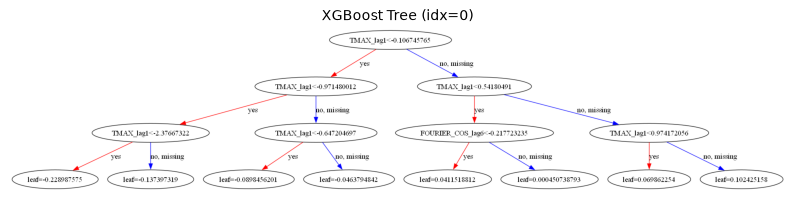

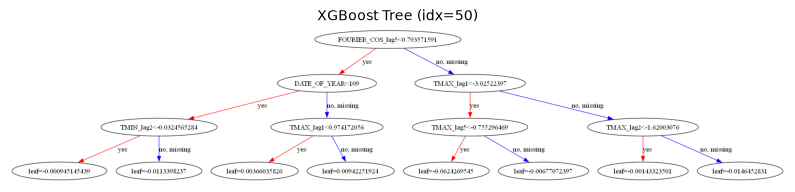

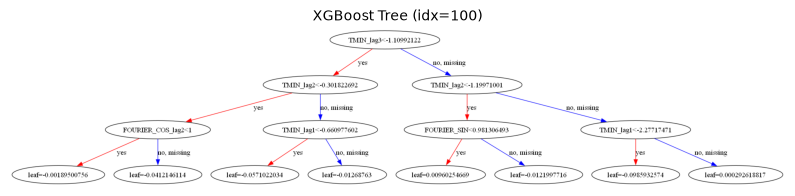

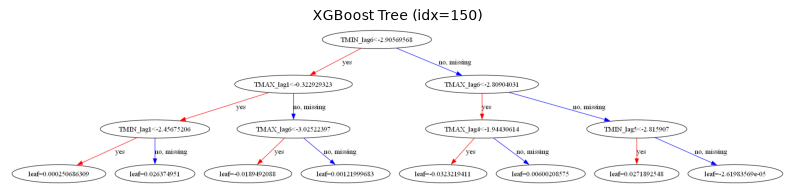

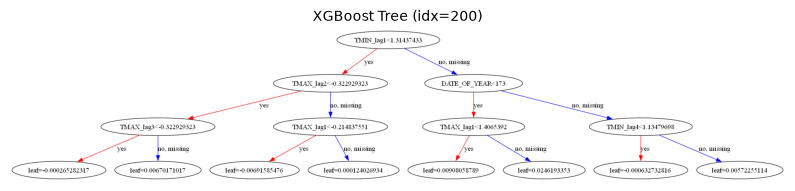

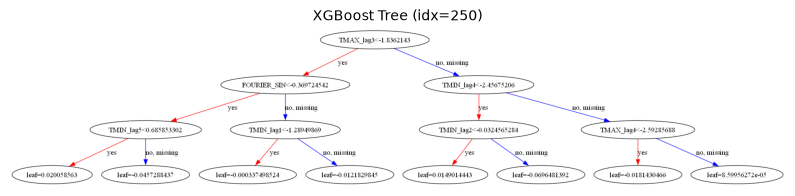

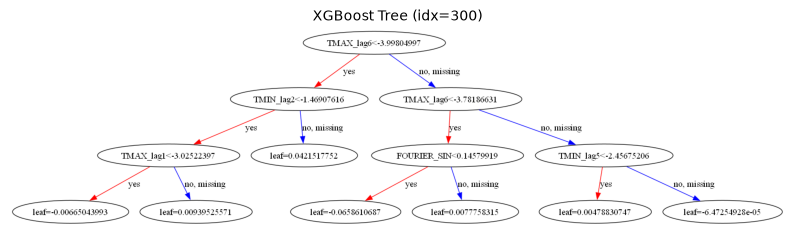

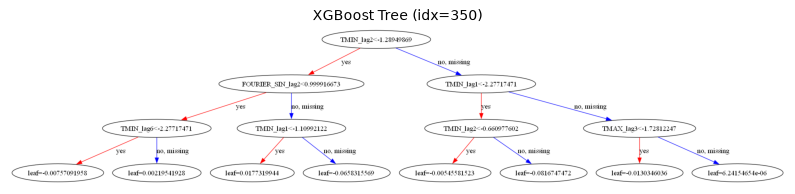

In [35]:
num_trees = len(xgboost_model.get_booster().get_dump())
for tree_idx in range(0, num_trees, 50):
    fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(10,10))
    xgb.plot_tree(xgboost_model, ax=ax, tree_idx=tree_idx)
    ax.set_title(f'XGBoost Tree (idx={tree_idx})', fontsize=10)
    ax.grid(False)
    fig.savefig(os.path.join(FIGURES_PATH, TREE_PLOT_DIR, f'xgboost_tree_idx={tree_idx}.png'))

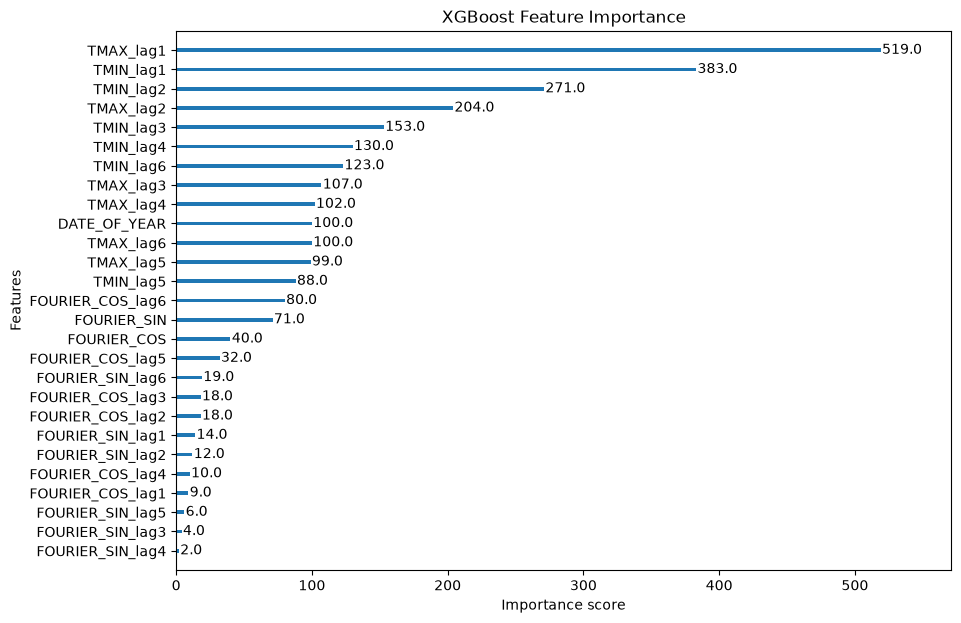

In [36]:
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(10,7))
xgb.plot_importance(xgboost_model, ax=ax)
ax.set_title('XGBoost Feature Importance')
ax.grid(False)
fig.savefig(os.path.join(FIGURES_PATH, TREE_PLOT_DIR, r'xgboost_feature_plot.png'))
plt.show()

### RNN

In [37]:
rnn_train_df = raw_ghcnd[(1980 <= raw_ghcnd.DATE.map(lambda x: x.year)) & (raw_ghcnd.DATE.map(lambda x: x.year) <= 2010)]
rnn_val_df = raw_ghcnd[raw_ghcnd.DATE.between('2010-12-26', '2018-01-01', inclusive="left")] # The start at 6 days before new years day enables the collections of lag features from 6 days back
rnn_test_df = raw_ghcnd[raw_ghcnd.DATE.between('2017-12-26', '2026-01-01', inclusive="left")] # The start at 6 days before new years day enables the collections of lag features from 6 days back

In [38]:
BATCH_SIZE = 64
EPOCHS = 100

In [39]:
rnn_train_dataset = RNN_GHCND_Dataset(rnn_train_df)
rnn_val_dataset = RNN_GHCND_Dataset(rnn_val_df)
rnn_test_dataset = RNN_GHCND_Dataset(rnn_test_df)

rnn_train_dataloader = DataLoader(rnn_train_dataset, batch_size=BATCH_SIZE, shuffle=True)
rnn_val_dataloader = DataLoader(rnn_val_dataset, batch_size=BATCH_SIZE, shuffle=True)
rnn_test_dataloader = DataLoader(rnn_test_dataset, batch_size=BATCH_SIZE, shuffle=True)

In [40]:
device = torch.device(torch.accelerator.current_accelerator() if torch.accelerator.is_available() else "cpu")
loss_fn = nn.MSELoss()

best_state_dict = None
best_hyperparameters = None
best_val_metrics = None

for NN_HIDDEN_SIZE in [16, 32, 64, 128]:
    for RNN_HIDDEN_SIZE in [16, 32, 64, 128]:
        for LEARNING_RATE in [0.001, 0.01, 0.1]:
            print(f"Config: (NN_HIDDEN: {NN_HIDDEN_SIZE} | RNN_HIDDEN: {RNN_HIDDEN_SIZE} | LR: {LEARNING_RATE})")
            
            rnn_model = WeatherRNN(RNN_HIDDEN_SIZE, NN_HIDDEN_SIZE).to(device)
            optimizer = optim.Adam(rnn_model.parameters(), lr=LEARNING_RATE)

            local_best_val_metrics = None
            local_best_state_dict = None

            local_end = 0
            current_trend = 0
            for epoch_index in range(EPOCHS):
                rnn_train_metrics = train_one_epoch(rnn_model, loss_fn, device, rnn_train_dataloader, optimizer)
                rnn_val_metrics, _ = evaluate_model(rnn_model, loss_fn, device, rnn_val_dataloader)

                if (local_best_val_metrics is None or rnn_val_metrics["RMSE"].mean() < local_best_val_metrics["RMSE"].mean()):
                    local_best_val_metrics = rnn_val_metrics
                    local_best_state_dict = copy.deepcopy(rnn_model.state_dict())
                    local_end = epoch_index + 1
                    current_trend = 0
                else:
                    current_trend += 1

                if (current_trend >= 5):
                    break

            print(f"- Final Metrics:")
            print(f"\t- MAE: {local_best_val_metrics["MAE"]}")
            print(f"\t- RMSE: {local_best_val_metrics["RMSE"]}")
            print(f"\t- ME: {local_best_val_metrics["ME"]}")
            print(f"\t- Loss: {local_best_val_metrics["total_loss"]}")
            print(f"\t- Last Epoch: {local_end}")

            if (best_val_metrics is None or local_best_val_metrics["RMSE"].mean() < best_val_metrics["RMSE"].mean()):
                best_state_dict = local_best_state_dict
                best_val_metrics = local_best_val_metrics
                best_hyperparameters = {
                    "nn_hidden_size": NN_HIDDEN_SIZE,
                    "rnn_hidden_size": RNN_HIDDEN_SIZE,
                    "lr": LEARNING_RATE,
                    "epochs": local_end
                }

best_rnn_model = WeatherRNN(RNN_HIDDEN=best_hyperparameters["rnn_hidden_size"], NN_HIDDEN=best_hyperparameters['nn_hidden_size'])
best_rnn_model.load_state_dict(best_state_dict)
best_rnn_model.to(device)
best_rnn_model.eval()

rnn_train_metrics, rnn_train_performance_df = evaluate_model(best_rnn_model, loss_fn, device, rnn_train_dataloader)
rnn_val_metrics, rnn_val_performance_df = evaluate_model(best_rnn_model, loss_fn, device, rnn_val_dataloader)
rnn_test_metrics, rnn_test_performance_df = evaluate_model(best_rnn_model, loss_fn, device, rnn_test_dataloader)

Config: (NN_HIDDEN: 16 | RNN_HIDDEN: 16 | LR: 0.001)
- Final Metrics:
	- MAE: [2.70554024 2.50184913]
	- RMSE: [3.73147986 3.51430148]
	- ME: [-0.13244601 -0.23747116]
	- Loss: 0.13112672687299465
	- Last Epoch: 19
Config: (NN_HIDDEN: 16 | RNN_HIDDEN: 16 | LR: 0.01)
- Final Metrics:
	- MAE: [2.707781   2.59571994]
	- RMSE: [3.71418237 3.53799223]
	- ME: [-0.05719522 -0.52463882]
	- Loss: 0.1310478149766469
	- Last Epoch: 10
Config: (NN_HIDDEN: 16 | RNN_HIDDEN: 16 | LR: 0.1)
- Final Metrics:
	- MAE: [2.81647535 2.75997517]
	- RMSE: [4.00054576 3.70950774]
	- ME: [ 0.73544743 -0.02785582]
	- Loss: 0.14896465070461173
	- Last Epoch: 4
Config: (NN_HIDDEN: 16 | RNN_HIDDEN: 32 | LR: 0.001)
- Final Metrics:
	- MAE: [2.72229409 2.5303228 ]
	- RMSE: [3.72482817 3.52102818]
	- ME: [-0.21488347 -0.4115495 ]
	- Loss: 0.1310277504057543
	- Last Epoch: 18
Config: (NN_HIDDEN: 16 | RNN_HIDDEN: 32 | LR: 0.01)
- Final Metrics:
	- MAE: [2.71079591 2.60306743]
	- RMSE: [3.70146394 3.55645763]
	- ME: [-0.2

#### RNN Metrics

In [41]:
best_val_metrics

{'MAE': array([2.68954198, 2.51584757]),
 'RMSE': array([3.71045612, 3.50637373]),
 'ME': array([-0.10801745, -0.29156299]),
 'total_loss': 0.1299883558279749}

In [42]:
best_hyperparameters

{'nn_hidden_size': 32, 'rnn_hidden_size': 128, 'lr': 0.001, 'epochs': 15}

In [43]:
print("Train Metrics: (TMAX/TMIN)")
print(f"- MAE: {rnn_train_metrics["MAE"]}")
print(f"- RMSE: {rnn_train_metrics["RMSE"]}")
print(f"- ME: {rnn_train_metrics["ME"]}\n")

print("Validation Metrics: (TMAX/TMIN)")
print(f"- MAE: {rnn_val_metrics["MAE"]}")
print(f"- RMSE: {rnn_val_metrics["RMSE"]}")
print(f"- ME: {rnn_val_metrics["ME"]}\n")

print("Test Metrics: (TMAX/TMIN)")
print(f"- MAE: {rnn_test_metrics["MAE"]}")
print(f"- RMSE: {rnn_test_metrics["RMSE"]}")
print(f"- ME: {rnn_test_metrics["ME"]}\n")

Train Metrics: (TMAX/TMIN)
- MAE: [2.6771949 2.774318 ]
- RMSE: [3.81206294 3.82386503]
- ME: [0.19651624 0.47338454]

Validation Metrics: (TMAX/TMIN)
- MAE: [2.68954198 2.51584757]
- RMSE: [3.71045612 3.50637373]
- ME: [-0.10801745 -0.29156299]

Test Metrics: (TMAX/TMIN)
- MAE: [2.69329076 2.60594481]
- RMSE: [3.69212651 3.52788865]
- ME: [-0.43941889 -0.53172791]



#### Comparing RNN with Climatological

In [44]:
print("Train Metrics: (TMAX/TMIN)")
print(f"- Baseline: {baseline_skill(climatological_train_metrics, xgboost_train_metrics)}\n")

print("Validation Metrics: (TMAX/TMIN)")
print(f"- Baseline: {baseline_skill(climatological_val_metrics, xgboost_val_metrics)}\n")

print("Test Metrics: (TMAX/TMIN)")
print(f"- Baseline: {baseline_skill(climatological_test_metrics, xgboost_test_metrics)}\n")

Train Metrics: (TMAX/TMIN)
- Baseline: [0.33731721 0.44213524]

Validation Metrics: (TMAX/TMIN)
- Baseline: [0.32121405 0.47568095]

Test Metrics: (TMAX/TMIN)
- Baseline: [0.36384865 0.49477796]



#### Comparing RNN with Persistence

In [45]:
print("Train Metrics: (TMAX/TMIN)")
print(f"- Baseline: {baseline_skill(persistence_train_metrics, xgboost_train_metrics)}\n")

print("Validation Metrics: (TMAX/TMIN)")
print(f"- Baseline: {baseline_skill(persistence_val_metrics, xgboost_val_metrics)}\n")

print("Test Metrics: (TMAX/TMIN)")
print(f"- Baseline: {baseline_skill(persistence_test_metrics, xgboost_test_metrics)}\n")

Train Metrics: (TMAX/TMIN)
- Baseline: [0.15153514 0.23422416]

Validation Metrics: (TMAX/TMIN)
- Baseline: [0.06696052 0.15016542]

Test Metrics: (TMAX/TMIN)
- Baseline: [0.05057669 0.10475131]



# Final Performance Summary Plots

## Train, Val, Test Set Predictions Overtime

In [46]:
PREDICTION_PLOT_DIR = "prediction_plots"
os.makedirs(os.path.join(FIGURES_PATH, PREDICTION_PLOT_DIR), exist_ok=True)

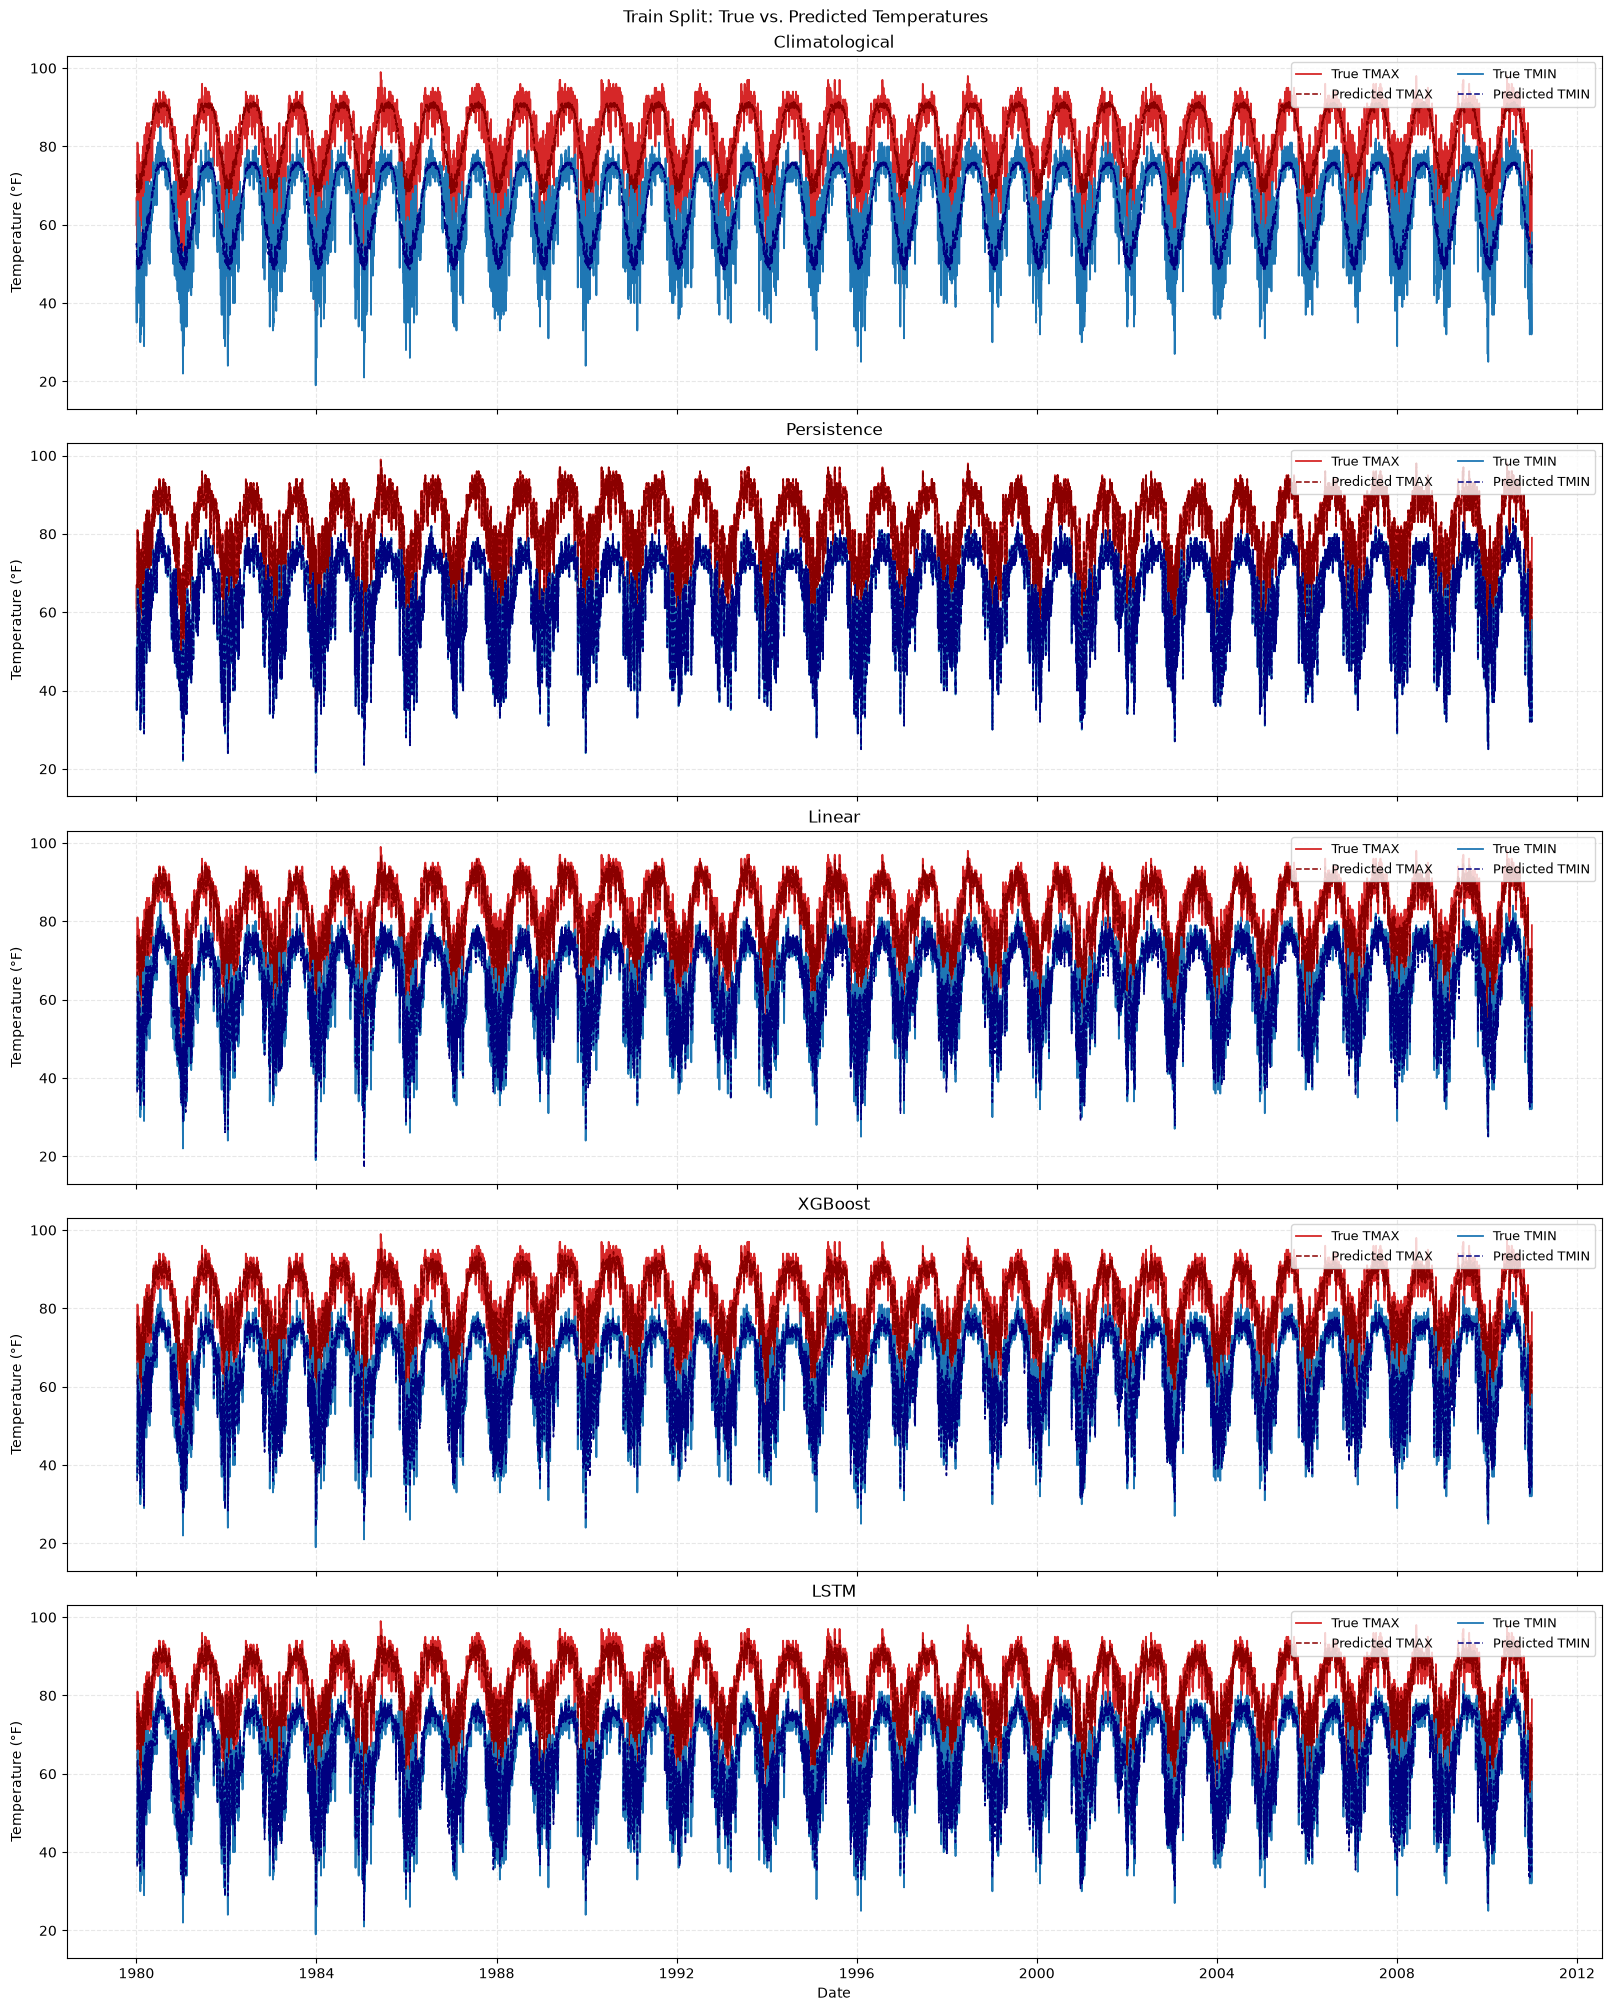

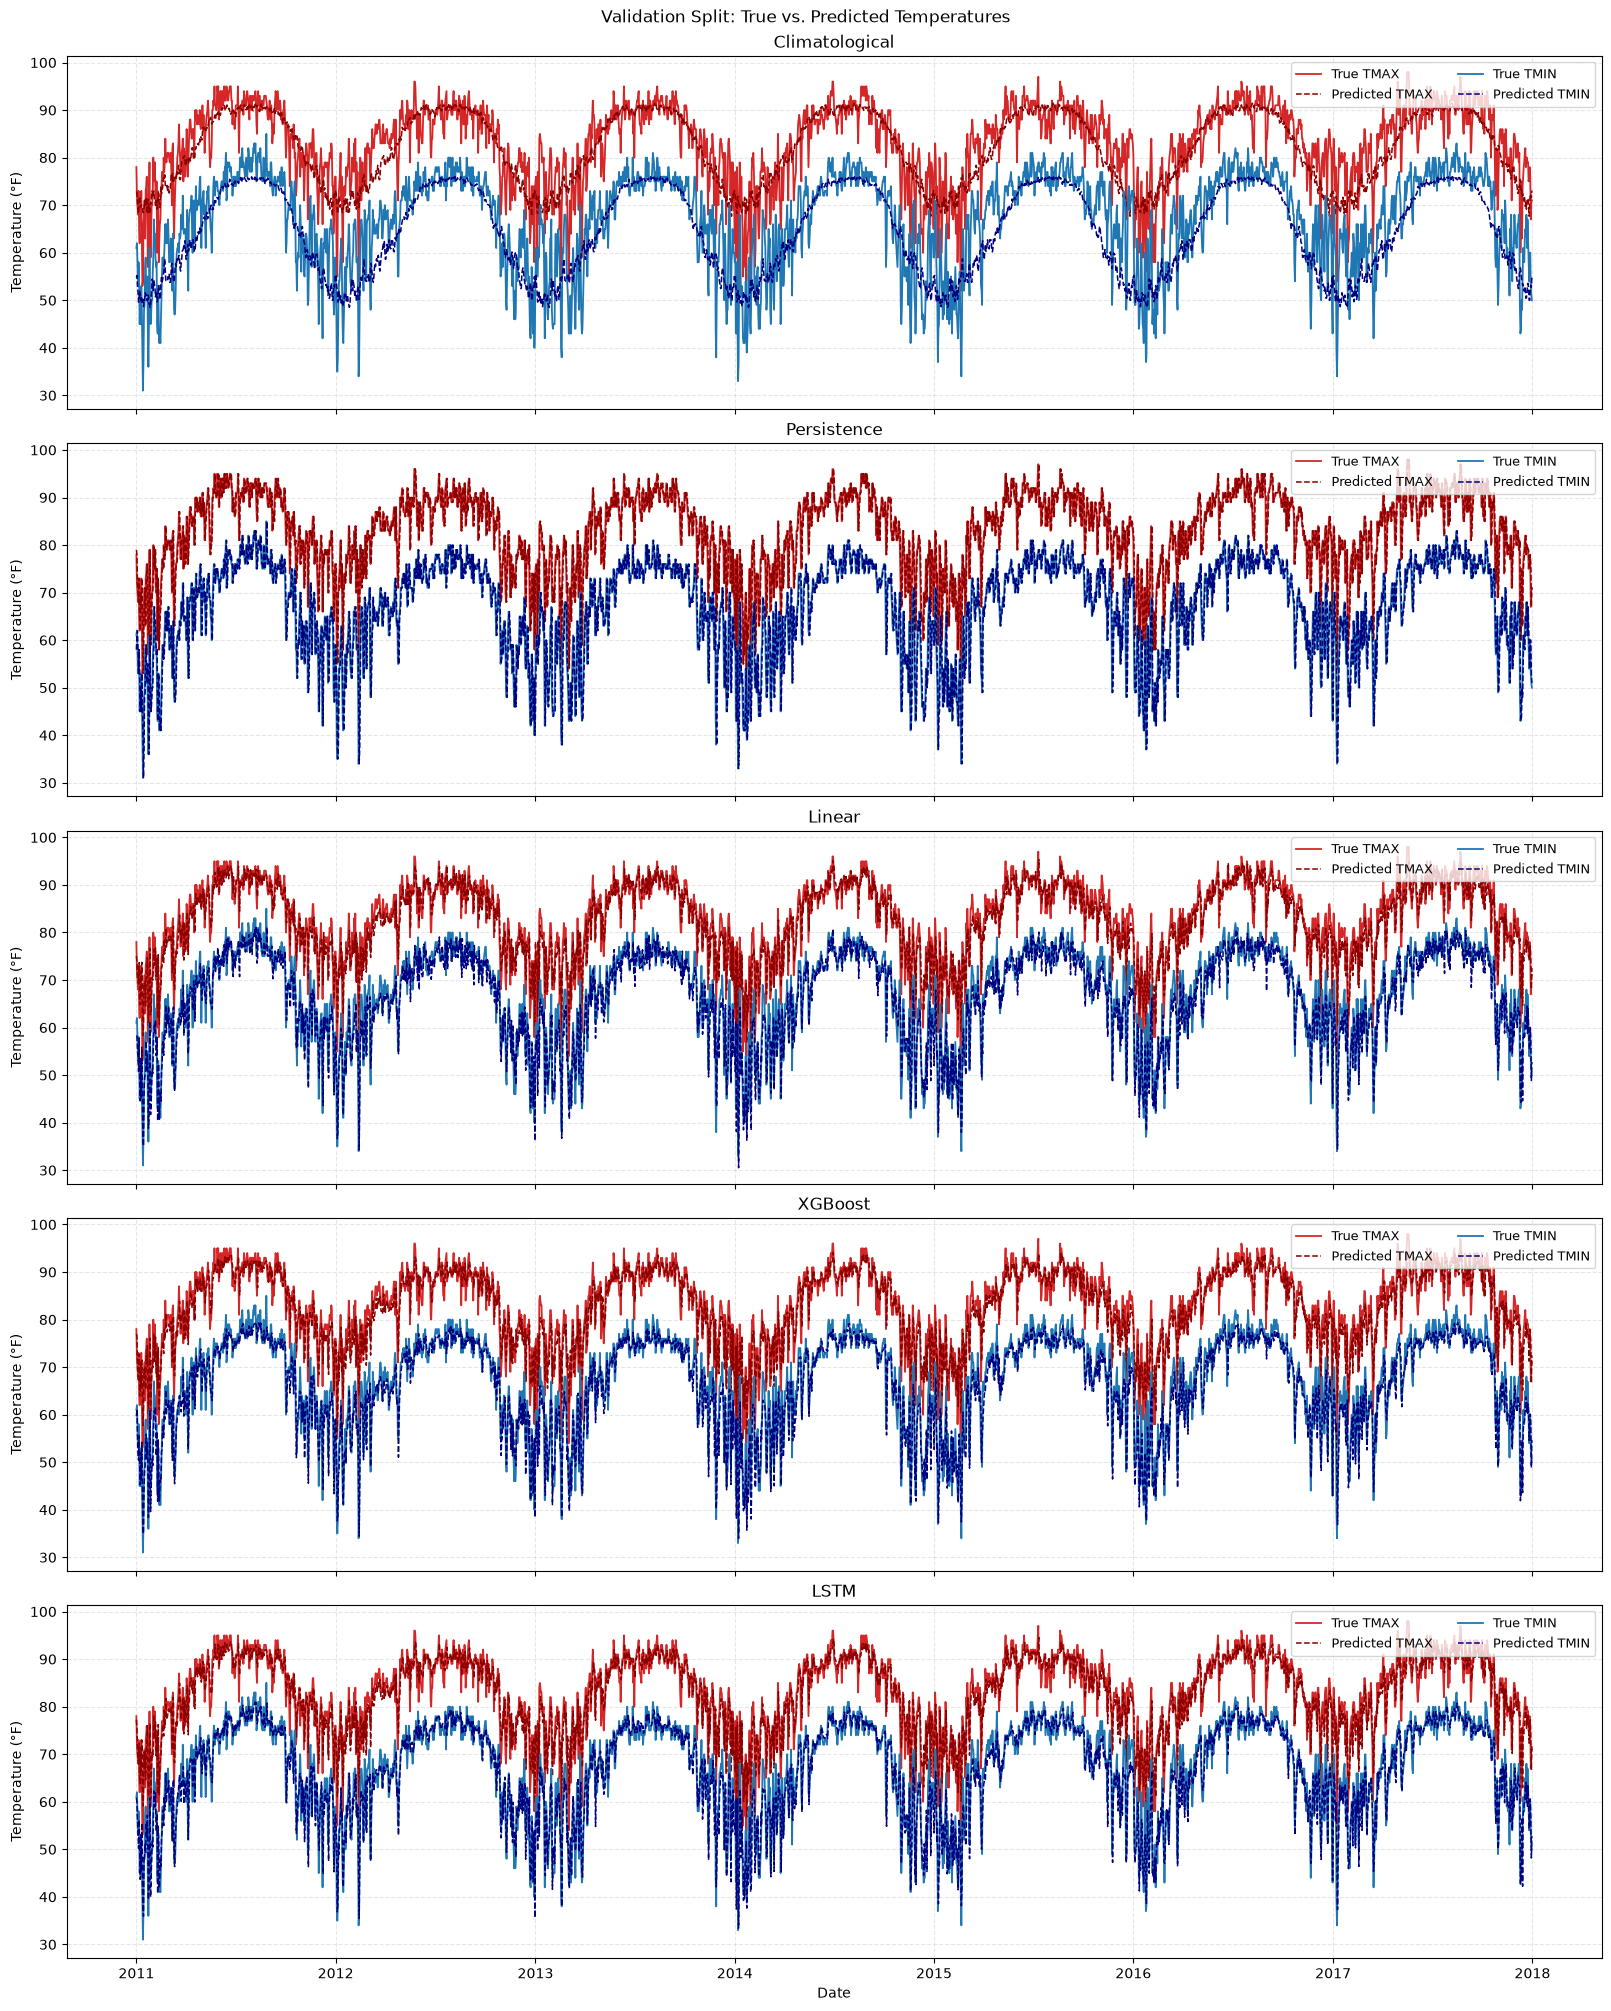

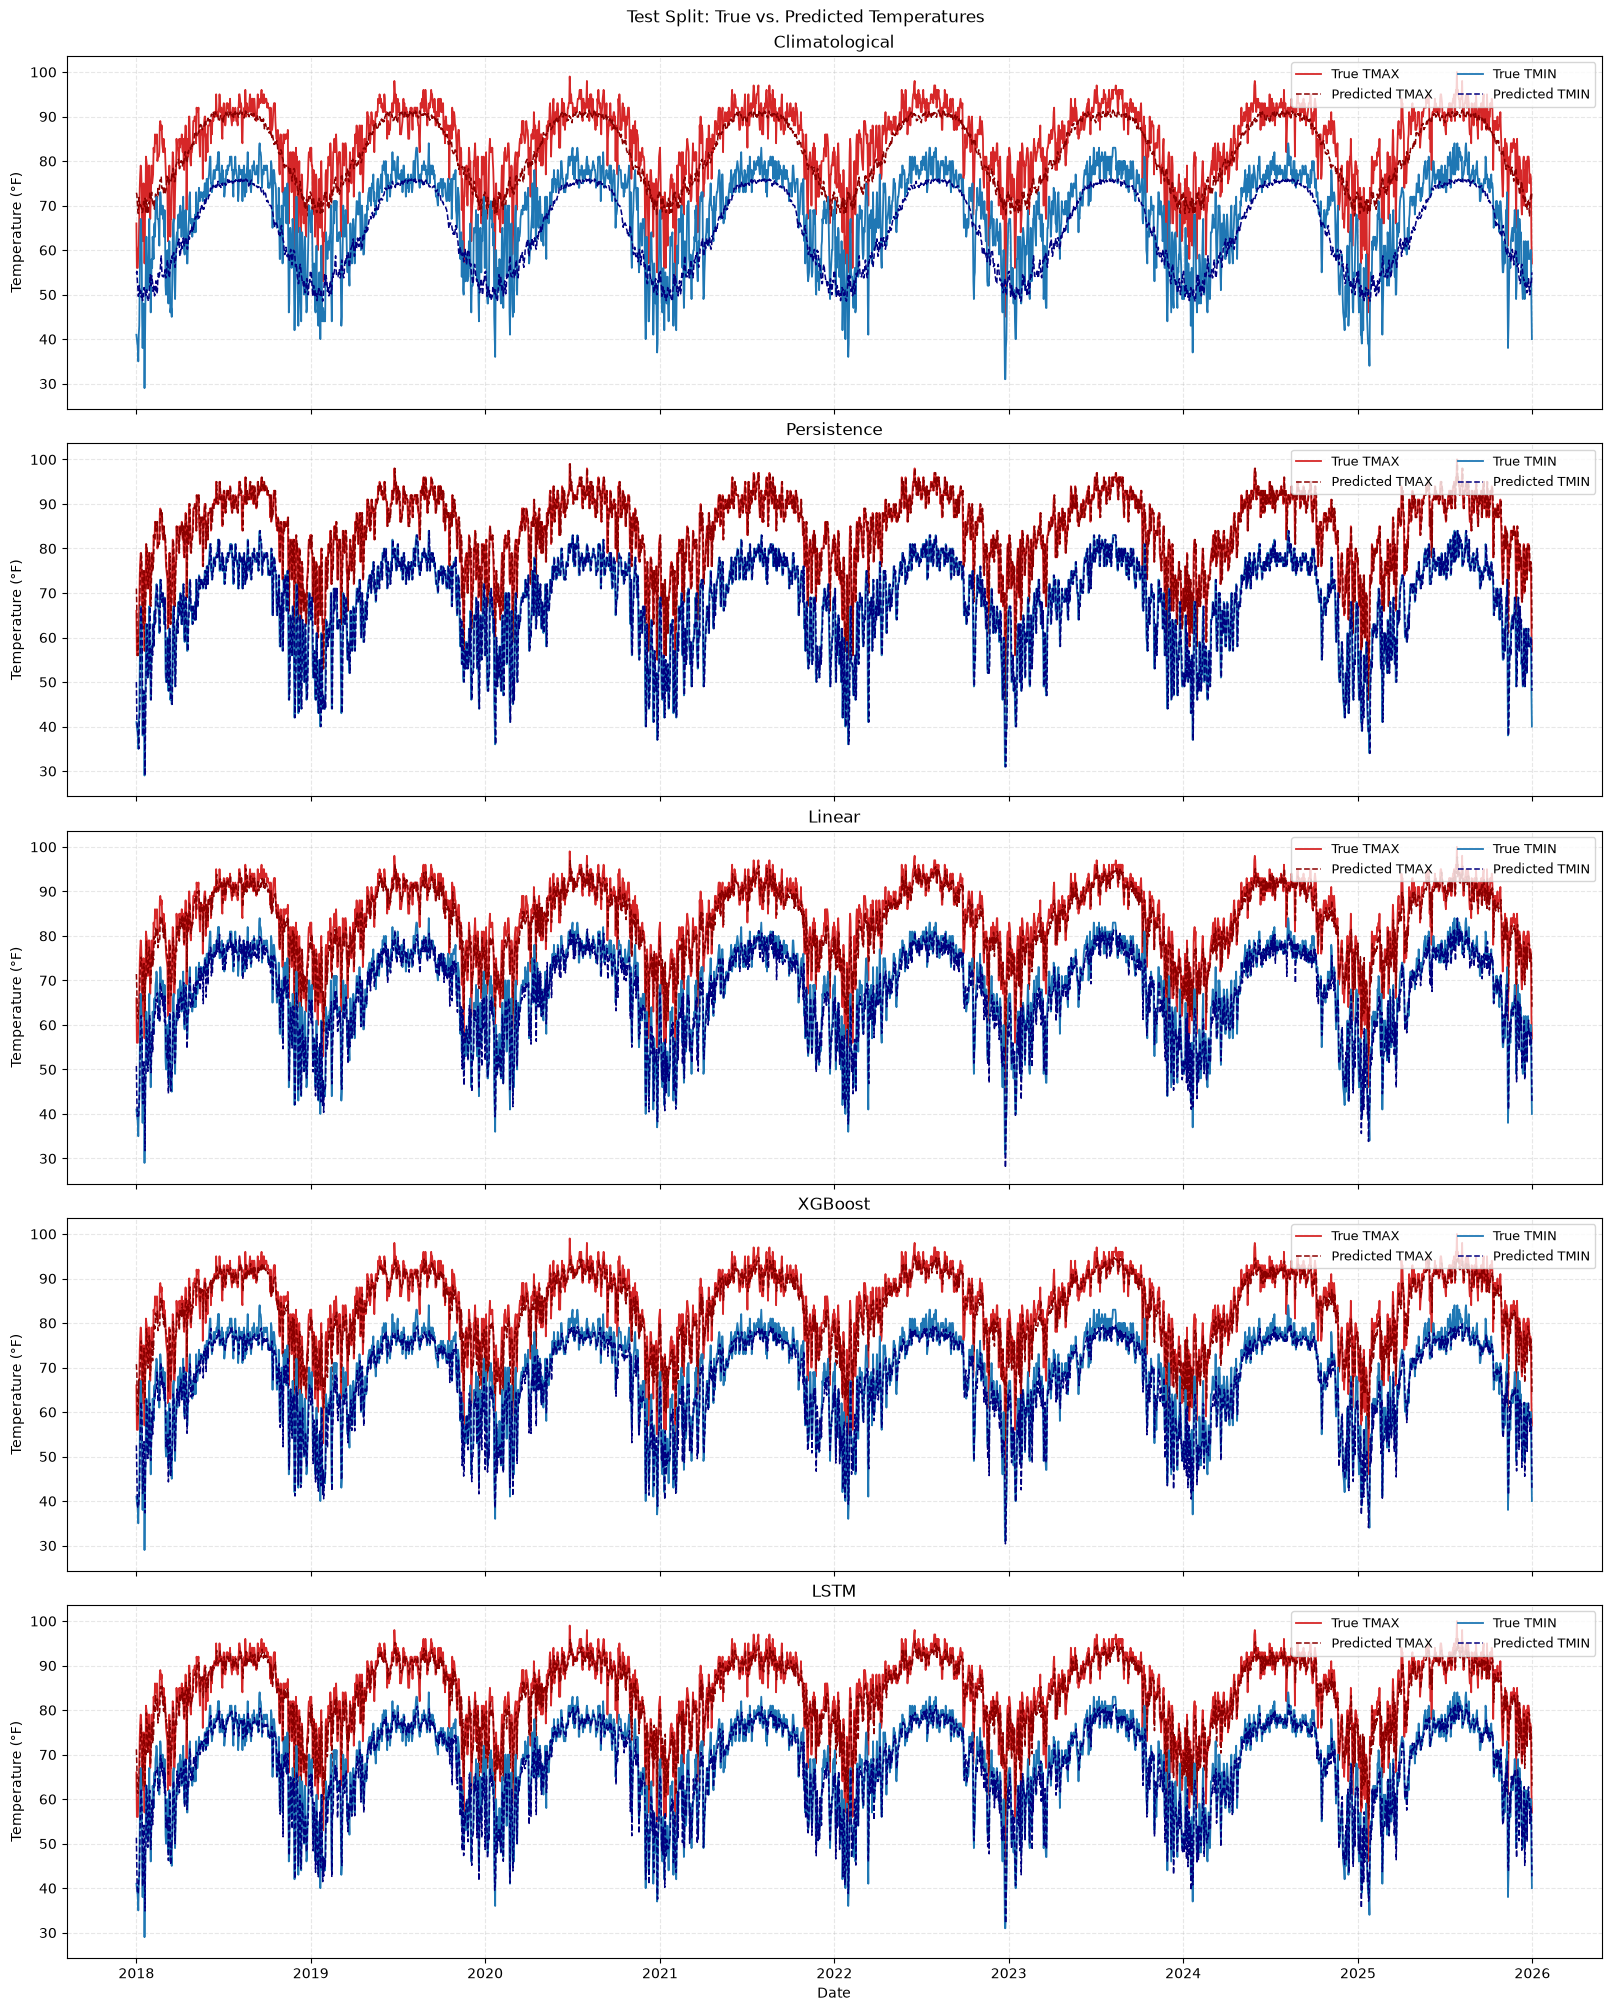

In [47]:
model_performance = {
    "Climatological": (
        climatological_train_performance_df,
        climatological_val_performance_df,
        climatological_test_performance_df,
    ),
    "Persistence": (
        persistence_train_performance_df,
        persistence_val_performance_df,
        persistence_test_performance_df,
    ),
    "Linear": (
        linear_train_performance_df,
        linear_val_performance_df,
        linear_test_performance_df,
    ),
    "XGBoost": (
        xgboost_train_performance_df,
        xgboost_val_performance_df,
        xgboost_test_performance_df,
    ),
    "LSTM": (
        rnn_train_performance_df,
        rnn_val_performance_df,
        rnn_test_performance_df,
    ),
}

split_names = ["Train", "Validation", "Test"]
model_names = list(model_performance)


def find_temperature_columns(performance_df, target):
    normalized_columns = {
        "".join(character for character in column.lower() if character.isalnum()): column
        for column in performance_df.columns
    }

    if target == "TMAX":
        actual_candidates = ("tmax", "actualtmax", "truetmax")
        predicted_candidates = (
            "predictedtmax",
            "predtmax",
            "forecasttmax",
            "tmaxpred",
            "tmaxprediction",
        )
    else:
        actual_candidates = ("tmin", "actualtmin", "truetmin")
        predicted_candidates = (
            "predictedtmin",
            "predtmin",
            "forecasttmin",
            "tminpred",
            "tminprediction",
        )

    for candidate in predicted_candidates:
        if candidate in normalized_columns:
            predicted_column = normalized_columns[candidate]
            break
    else:
        predicted_column = None

    for candidate in actual_candidates:
        if candidate in normalized_columns:
            actual_column = normalized_columns[candidate]
            break
    else:
        actual_column = None

    return actual_column, predicted_column


for split_index, split_name in enumerate(split_names):
    fig, axes = plt.subplots(
        len(model_names),
        1,
        figsize=(16, 20),
        sharex=True,
        sharey=True,
        constrained_layout=True,
    )

    for ax, model_name in zip(axes, model_names):
        performance_df = model_performance[model_name][split_index].copy()
        performance_df = performance_df.sort_index()

        actual_tmax, predicted_tmax = find_temperature_columns(
            performance_df, "TMAX"
        )
        actual_tmin, predicted_tmin = find_temperature_columns(
            performance_df, "TMIN"
        )

        if actual_tmax is not None:
            ax.plot(
                performance_df.index,
                performance_df[actual_tmax],
                color="tab:red",
                linewidth=1.3,
                label="True TMAX",
            )

        if predicted_tmax is not None:
            ax.plot(
                performance_df.index,
                performance_df[predicted_tmax],
                color="darkred",
                linestyle="--",
                linewidth=1.1,
                label="Predicted TMAX",
            )

        if actual_tmin is not None:
            ax.plot(
                performance_df.index,
                performance_df[actual_tmin],
                color="tab:blue",
                linewidth=1.3,
                label="True TMIN",
            )

        if predicted_tmin is not None:
            ax.plot(
                performance_df.index,
                performance_df[predicted_tmin],
                color="navy",
                linestyle="--",
                linewidth=1.1,
                label="Predicted TMIN",
            )

        ax.set_title(model_name)
        ax.set_ylabel("Temperature (°F)")
        ax.grid(True, linestyle="--", alpha=0.3)
        ax.legend(loc="upper right", ncols=2, fontsize=9)

    axes[-1].set_xlabel("Date")
    fig.suptitle(f"{split_name} Split: True vs. Predicted Temperatures")

    figure_path = os.path.join(
        FIGURES_PATH,
        PREDICTION_PLOT_DIR,
        f"{split_name.lower()}_model_predictions.png",
    )
    fig.savefig(figure_path, dpi=300, bbox_inches="tight")
    plt.show()

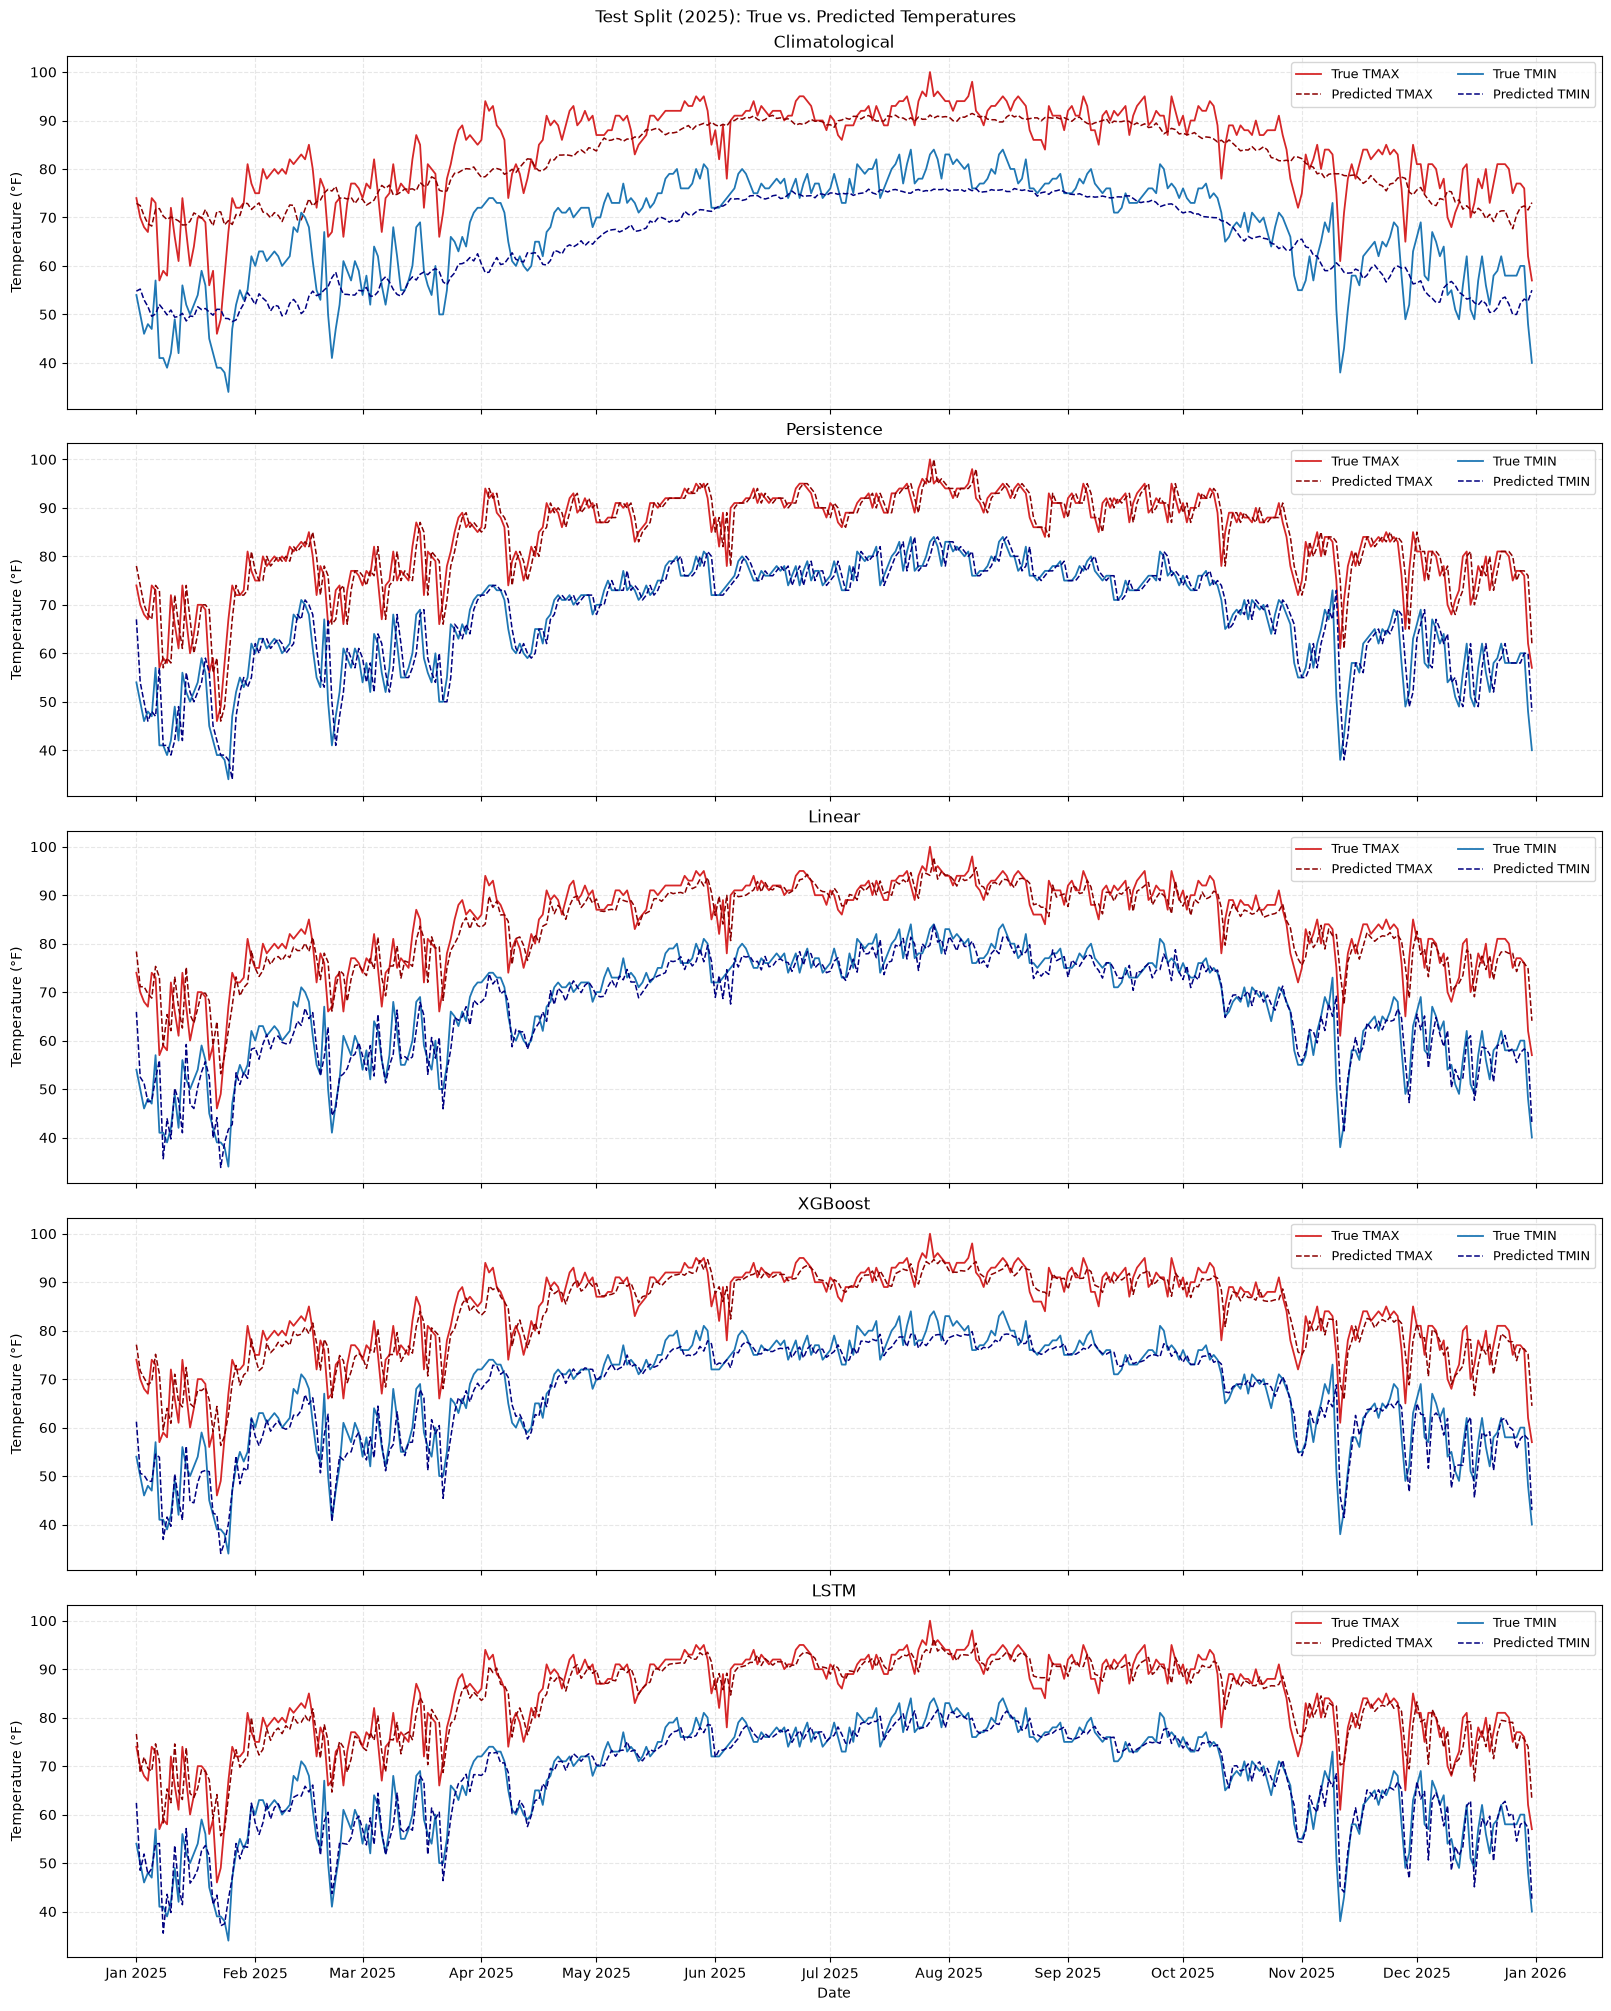

In [48]:
start_2025 = pd.Timestamp("2025-01-01")
end_2025 = pd.Timestamp("2025-12-31")

fig, axes = plt.subplots(
    len(model_names),
    1,
    figsize=(16, 20),
    sharex=True,
    sharey=True,
    constrained_layout=True,
)

for ax, model_name in zip(axes, model_names):
    performance_df = model_performance[model_name][2].copy()
    performance_df.index = pd.to_datetime(performance_df.index)
    performance_df = performance_df.loc[
        (performance_df.index >= start_2025)
        & (performance_df.index <= end_2025)
    ].sort_index()

    actual_tmax, predicted_tmax = find_temperature_columns(
        performance_df, "TMAX"
    )
    actual_tmin, predicted_tmin = find_temperature_columns(
        performance_df, "TMIN"
    )

    if actual_tmax is not None:
        ax.plot(
            performance_df.index,
            performance_df[actual_tmax],
            color="tab:red",
            linewidth=1.3,
            label="True TMAX",
        )

    if predicted_tmax is not None:
        ax.plot(
            performance_df.index,
            performance_df[predicted_tmax],
            color="darkred",
            linestyle="--",
            linewidth=1.1,
            label="Predicted TMAX",
        )

    if actual_tmin is not None:
        ax.plot(
            performance_df.index,
            performance_df[actual_tmin],
            color="tab:blue",
            linewidth=1.3,
            label="True TMIN",
        )

    if predicted_tmin is not None:
        ax.plot(
            performance_df.index,
            performance_df[predicted_tmin],
            color="navy",
            linestyle="--",
            linewidth=1.1,
            label="Predicted TMIN",
        )

    ax.set_title(model_name)
    ax.set_ylabel("Temperature (°F)")
    ax.grid(True, linestyle="--", alpha=0.3)
    ax.legend(loc="upper right", ncols=2, fontsize=9)

axes[-1].set_xlabel("Date")
axes[-1].xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%b %Y"))
axes[-1].xaxis.set_major_locator(plt.matplotlib.dates.MonthLocator(interval=1))
fig.suptitle("Test Split (2025): True vs. Predicted Temperatures")

figure_path = os.path.join(
    FIGURES_PATH,
    PREDICTION_PLOT_DIR,
    "test_2025_model_predictions.png",
)
fig.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

## Metrics

In [49]:
METRIC_PLOT_DIR = 'metric_plots'
os.makedirs(os.path.join(FIGURES_PATH, METRIC_PLOT_DIR), exist_ok=True)

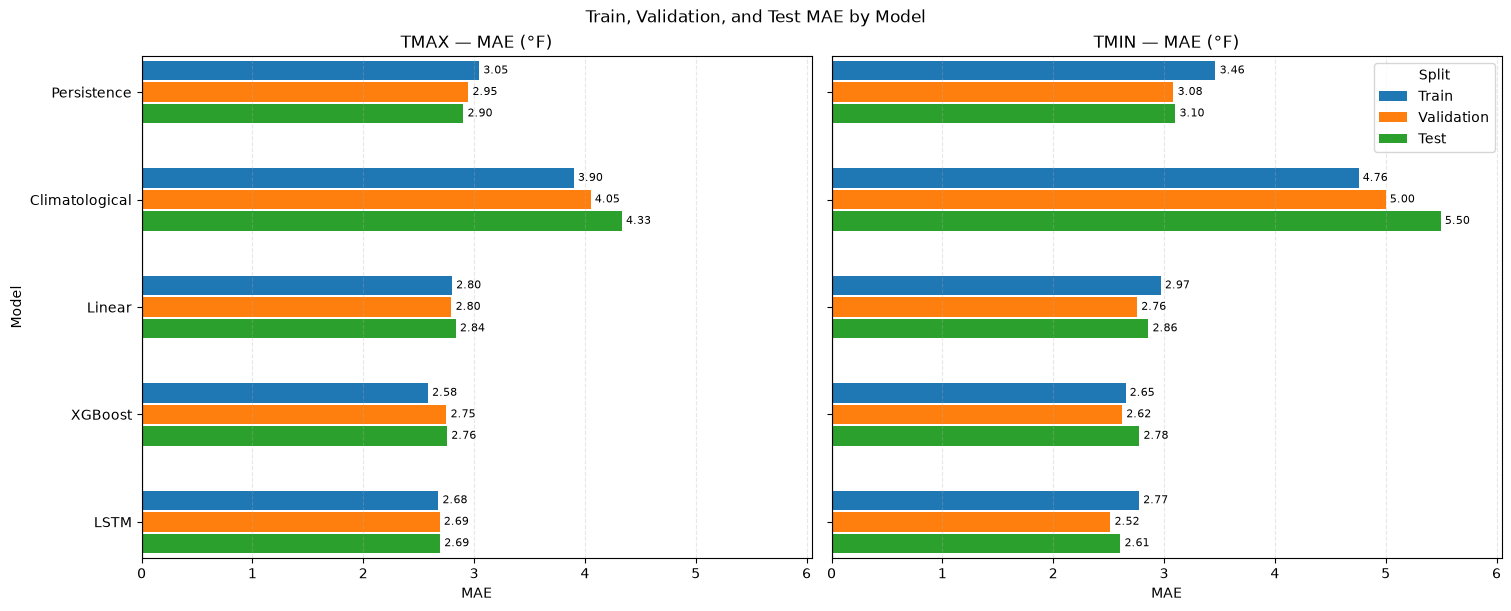

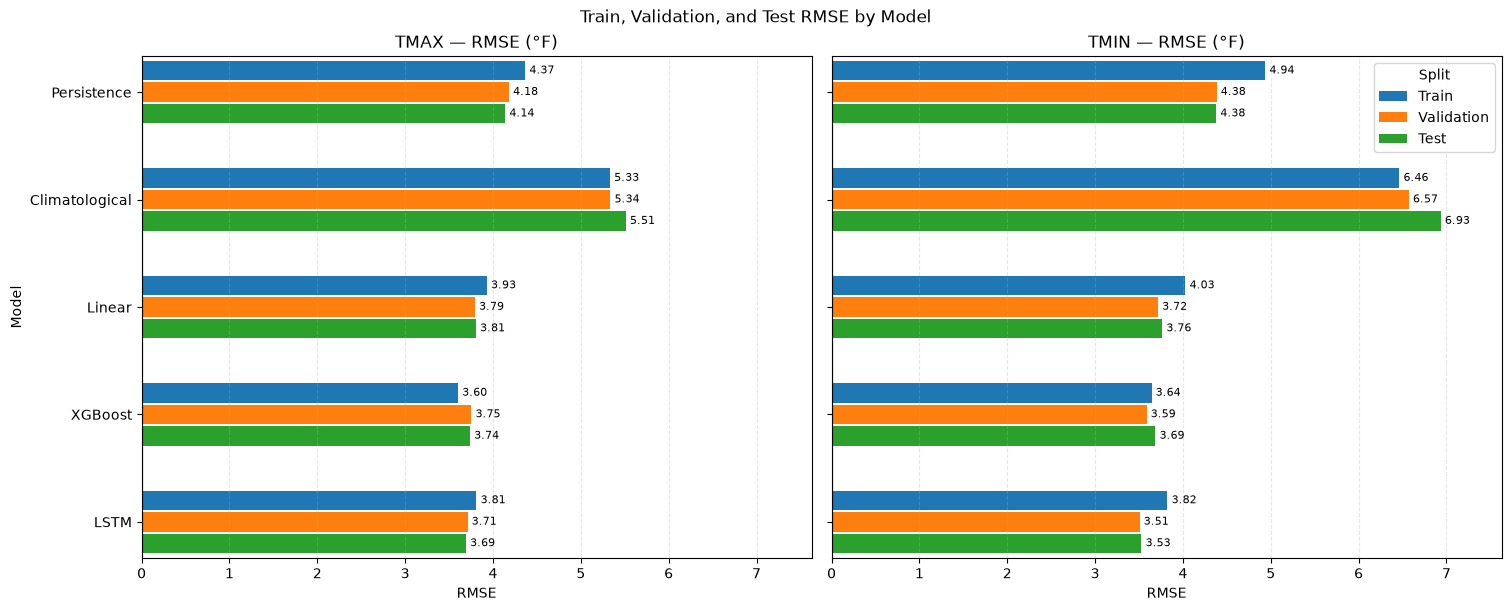

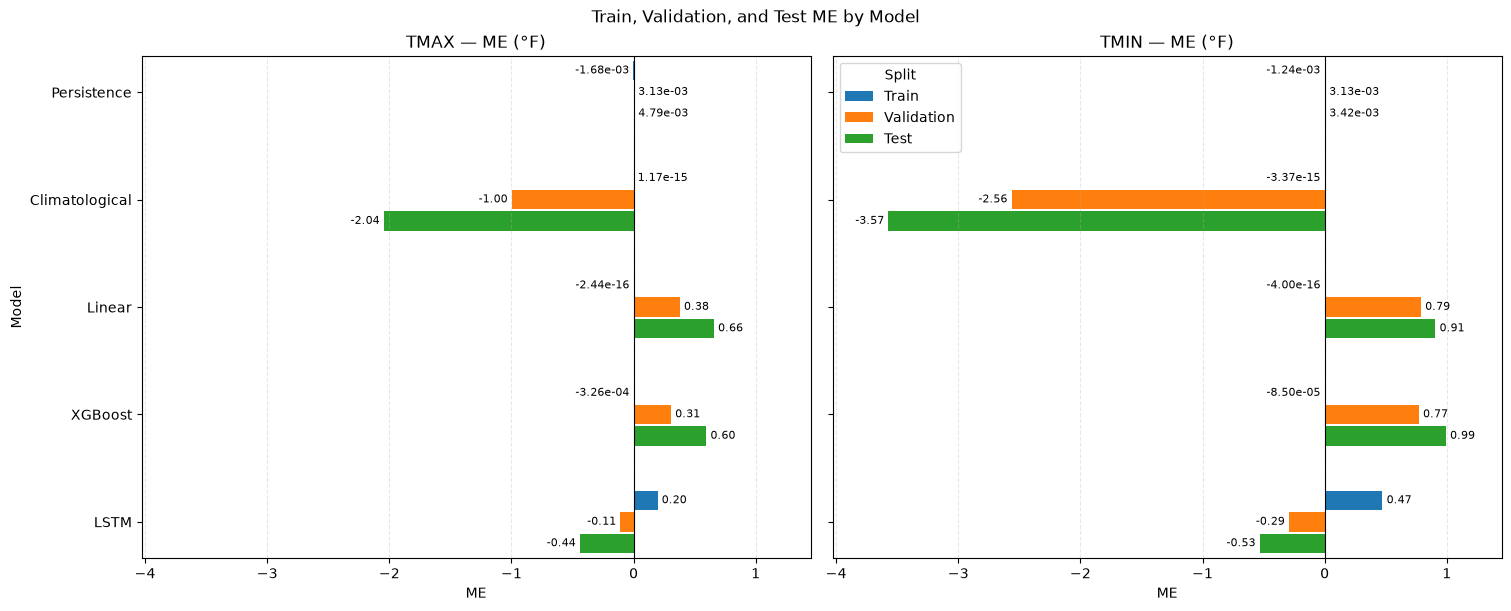

In [50]:
def plot_model_metrics(metric="MAE"):
    # Group each model's train, validation, and test metrics in split order.
    model_metrics = {
        "Persistence": (
            persistence_train_metrics,
            persistence_val_metrics,
            persistence_test_metrics,
        ),
        "Climatological": (
            climatological_train_metrics,
            climatological_val_metrics,
            climatological_test_metrics,
        ),
        "Linear": (
            linear_train_metrics,
            linear_val_metrics,
            linear_test_metrics,
        ),
        "XGBoost": (
            xgboost_train_metrics,
            xgboost_val_metrics,
            xgboost_test_metrics,
        ),
        "LSTM": (
            rnn_train_metrics,
            rnn_val_metrics,
            rnn_test_metrics,
        ),
    }

    # Validate that only supported error metrics are requested.
    if metric not in {"MAE", "RMSE", "ME"}:
        raise ValueError("metric must be 'MAE', 'RMSE', or 'ME'")

    # Define ordering and labels used consistently by the plot.
    split_names = ["Train", "Validation", "Test"]
    target_names = ["TMAX", "TMIN"]
    model_names = list(model_metrics)

    # Create one side-by-side chart for TMAX and TMIN.
    fig, axes = plt.subplots(
        1,
        2,
        figsize=(15, 6),
        sharex=True,
        sharey=True,
        constrained_layout=True,
    )

    # Control bar thickness and the offsets for grouping split bars.
    bar_height = 0.18
    split_spacing = 0.20
    model_positions = np.arange(len(model_names))

    # Draw one target variable in each subplot.
    for ax, target_name in zip(axes, target_names):
        bars_by_split = []

        # Plot Train, Validation, and Test bars beside each model position.
        for split_index, split_name in enumerate(split_names):
            values = [
                model_metrics[model_name][split_index][metric][
                    target_names.index(target_name)
                ]
                for model_name in model_names
            ]

            positions = model_positions + (split_index - 1) * split_spacing
            bars = ax.barh(
                positions,
                values,
                height=bar_height,
                label=split_name,
            )
            bars_by_split.append(bars)

            # Add the numeric value at the end of each horizontal bar.
            ax.bar_label(
                bars,
                labels=[
                    f"{value:.2f}" if abs(value) >= 0.01 else f"{value:.2e}"
                    for value in values
                ],
                padding=3,
                fontsize=8,
            )

        # Format axes, add a zero reference line, and improve readability.
        ax.axvline(0, color="black", linewidth=0.8)
        ax.set_title(f"{target_name} — {metric} (°F)")
        ax.set_xlabel(metric)
        ax.set_yticks(model_positions)
        ax.set_yticklabels(model_names)
        ax.set_yinverted(True)
        ax.grid(axis="x", linestyle="--", alpha=0.3)
        ax.margins(x=0.1, y=0.01)

    # Add shared labels and legend, then save and display the figure.
    axes[0].set_ylabel("Model")
    axes[1].legend(title="Split")
    fig.suptitle(f"Train, Validation, and Test {metric} by Model")

    figure_path = os.path.join(
        FIGURES_PATH,
        METRIC_PLOT_DIR,
        f"model_{metric}_comparison.png",
    )
    fig.savefig(figure_path, dpi=300, bbox_inches="tight")
    plt.show()

    return fig, axes


# Generate and save a comparison chart for each supported metric.
for metric_name in ["MAE", "RMSE", "ME"]:
    plot_model_metrics(metric_name)

## Baselines

In [51]:
BASELINE_PLOT_DIR = 'baseline_plots'
os.makedirs(os.path.join(FIGURES_PATH, BASELINE_PLOT_DIR), exist_ok=True)

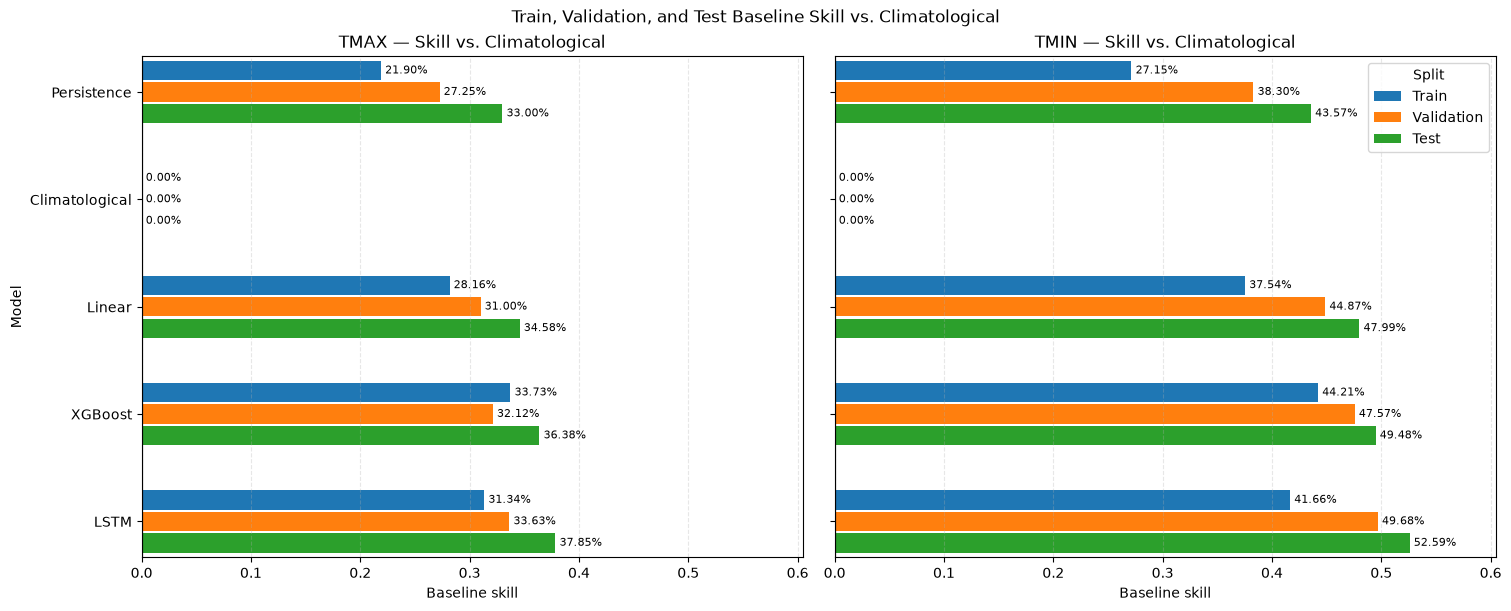

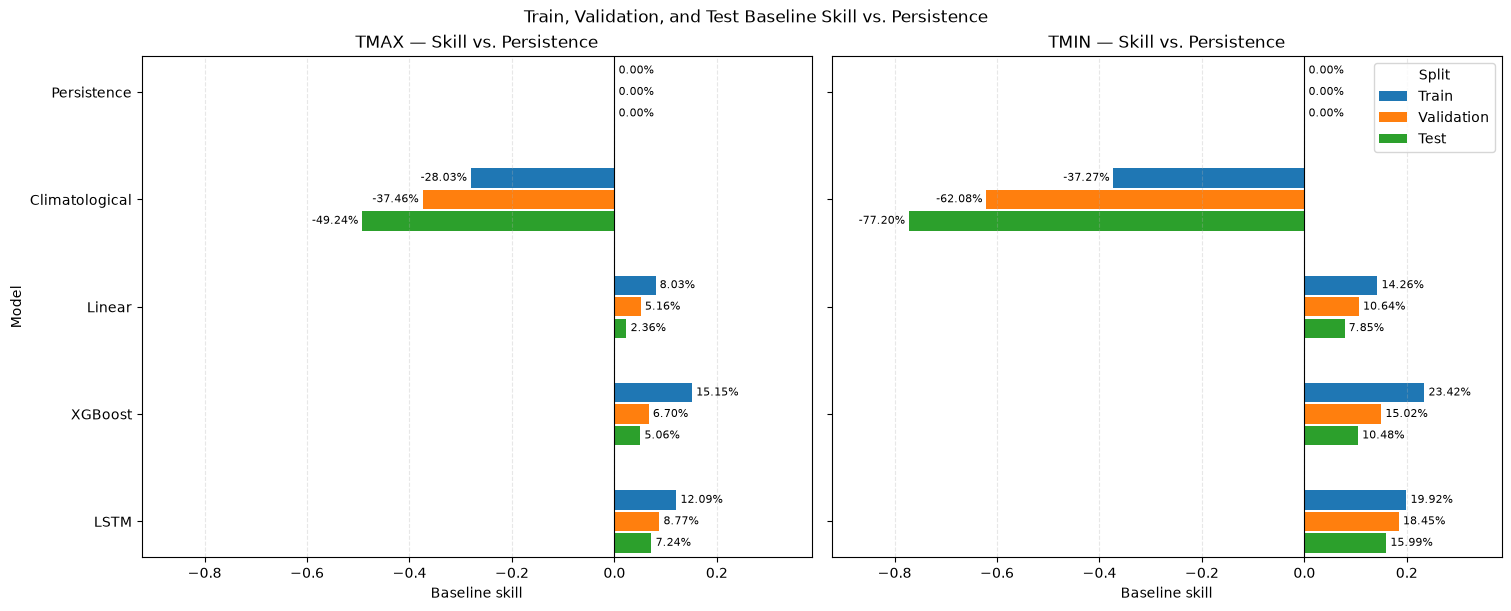

In [52]:
model_metrics = {
    "Persistence": (
        persistence_train_metrics,
        persistence_val_metrics,
        persistence_test_metrics,
    ),
    "Climatological": (
        climatological_train_metrics,
        climatological_val_metrics,
        climatological_test_metrics,
    ),
    "Linear": (
        linear_train_metrics,
        linear_val_metrics,
        linear_test_metrics,
    ),
    "XGBoost": (
        xgboost_train_metrics,
        xgboost_val_metrics,
        xgboost_test_metrics,
    ),
    "LSTM": (
        rnn_train_metrics,
        rnn_val_metrics,
        rnn_test_metrics,
    ),
}

baseline_metrics = {
    "Climatological": (
        climatological_train_metrics,
        climatological_val_metrics,
        climatological_test_metrics,
    ),
    "Persistence": (
        persistence_train_metrics,
        persistence_val_metrics,
        persistence_test_metrics,
    ),
}

split_names = ["Train", "Validation", "Test"]
model_names = list(model_metrics)
target_names = ["TMAX", "TMIN"]

for baseline_name, split_baselines in baseline_metrics.items():
    fig, axes = plt.subplots(
        1, 2, figsize=(15, 6), sharex=True, sharey=True, constrained_layout=True
    )

    model_positions = np.arange(len(model_names))
    split_spacing = 0.20
    bar_height = 0.18

    for target_index, (ax, target_name) in enumerate(zip(axes, target_names)):
        for split_index, split_name in enumerate(split_names):
            baseline = split_baselines[split_index]
            skills = [
                baseline_skill(baseline, model_metrics[model_name][split_index])[target_index]
                for model_name in model_names
            ]
            positions = model_positions + (split_index - 1) * split_spacing

            bars = ax.barh(
                positions,
                skills,
                height=bar_height,
                label=split_name,
            )
            ax.bar_label(
                bars,
                labels=[f"{skill:.2%}" for skill in skills],
                padding=3,
                fontsize=8,
            )

        ax.axvline(0, color="black", linewidth=0.8)
        ax.set_title(f"{target_name} — Skill vs. {baseline_name}")
        ax.set_xlabel("Baseline skill")
        ax.set_yticks(model_positions)
        ax.set_yticklabels(model_names)
        ax.set_yinverted(True)
        ax.grid(axis="x", linestyle="--", alpha=0.3)
        ax.margins(x=0.15, y=0.01)

    axes[0].set_ylabel("Model")
    axes[1].legend(title="Split")
    fig.suptitle(f"Train, Validation, and Test Baseline Skill vs. {baseline_name}")

    figure_path = os.path.join(
        FIGURES_PATH,
        BASELINE_PLOT_DIR,
        f"baseline_skill_{baseline_name.lower()}.png",
    )
    fig.savefig(figure_path, dpi=300, bbox_inches="tight")
    plt.show()